In [1]:
import warnings
warnings.filterwarnings("ignore")

C:\Users\DELL\AppData\Local\Temp\ipykernel_9476\2516766800.py:26: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


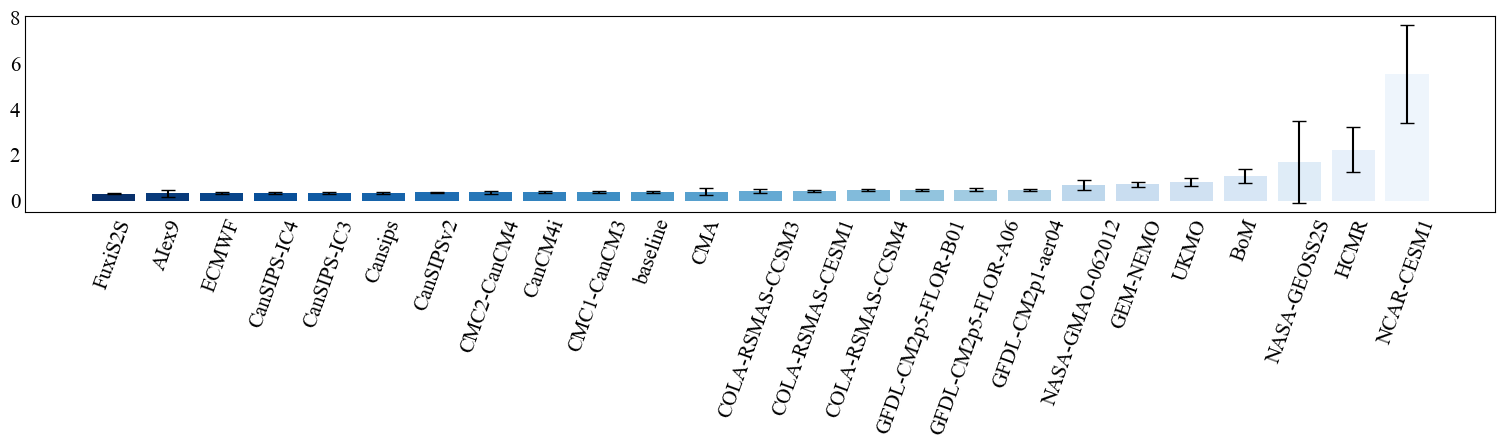

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import cmaps
plt.style.use('_mpl-gallery-nogrid')
data = pd.read_csv('../data/bar_ARMSE1.csv')

# Sort the data by 'ERROR' in ascending order
sorted_data = data.sort_values(by='Mean')
sorted_data = sorted_data[(sorted_data['Name'] != 'CNN') & (sorted_data['Name'] != 'Geoformer')].copy()
colors = [cmaps.MPL_Blues_r(i / len(sorted_data)) for i in range(len(sorted_data))]
# Create a bar plot for the sorted ERROR values with error bars
plt.figure(figsize=(15, 2))
plt.bar(sorted_data['Name'], sorted_data['Mean'], yerr=sorted_data['STD'], capsize=5, color=colors)
y_05th = sorted_data['Mean'].quantile(0.95)
y_95th = sorted_data['Mean'].quantile(0.05)



plt.xlabel('Name')
plt.ylabel('Mean')
plt.xticks(rotation=70)
plt.xticks(fontname='Times New Roman', fontsize=15)
plt.yticks(fontname='Times New Roman', fontsize=15)
plt.xlabel('')  # Remove x-axis label
plt.ylabel('')  # Remove y-axis label
plt.tight_layout()
plt.show()


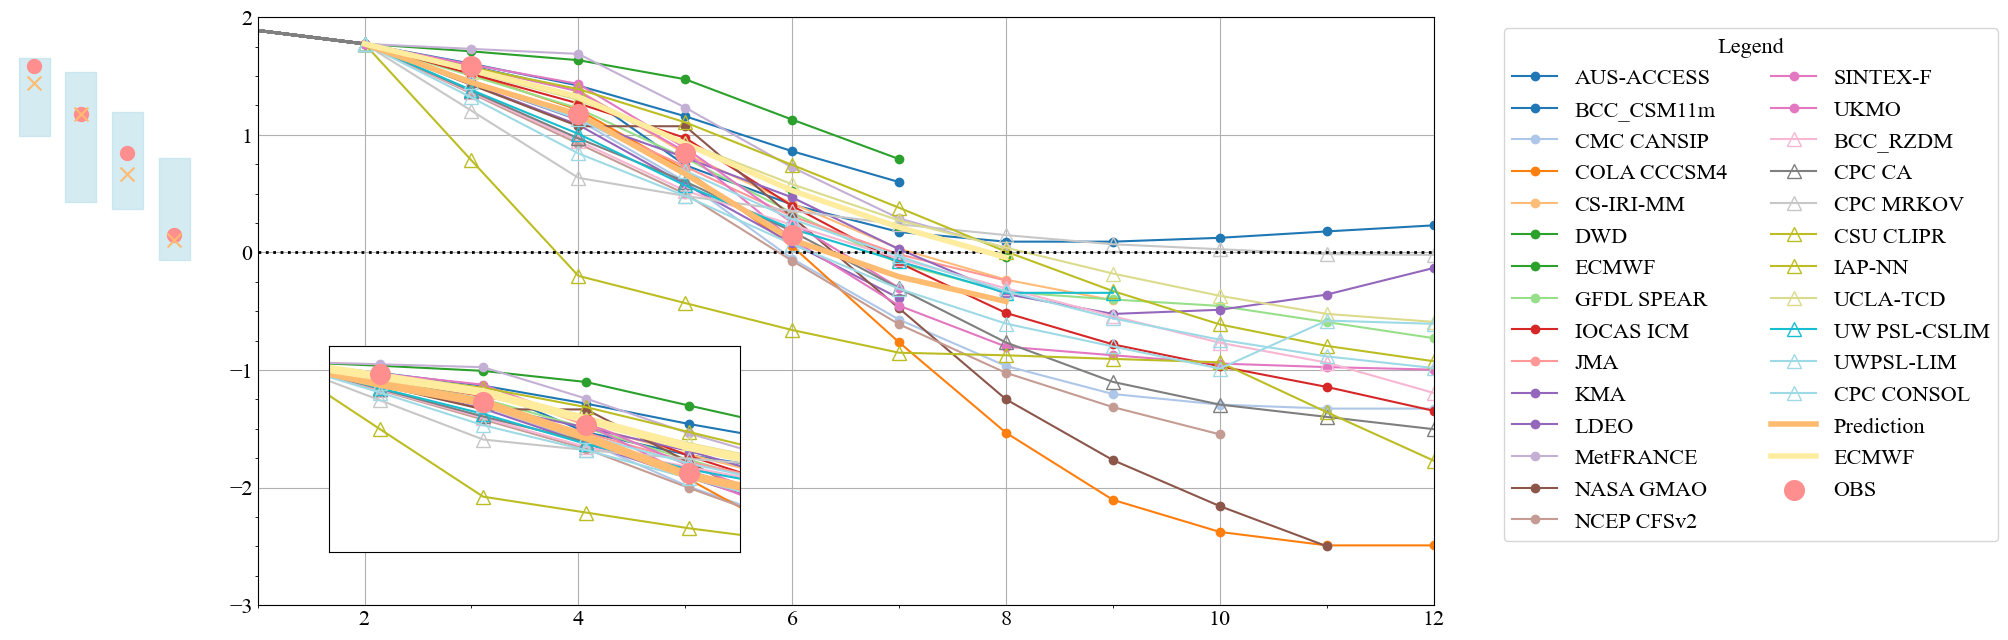

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import AutoMinorLocator
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.colors as mcolors
from matplotlib import rcParams
data = pd.read_csv('../data/oth.csv')
# Assuming the data is already loaded into the DataFrame `data`
# Dynamical and Statistical models
dynamical_columns = data.loc[:, 'AUS-ACCESS':'UKMO'].columns
statistical_columns = data.loc[:, 'BCC_RZDM':'CPC CONSOL'].columns

config = {"font.family": 'Times New Roman', "font.size": 16, "mathtext.fontset": 'stix'}
rcParams.update(config)

# Setting the color map
cmap = plt.get_cmap('tab20', len(dynamical_columns) + len(statistical_columns))

# Create the figure and axis
fig, ax = plt.subplots(figsize=(12, 6))

# Plot Dynamical Models with circles
for i, column in enumerate(dynamical_columns):
    # Plot first two points as grey line
    ax.plot(data['Date'][:2], data[column][:2], color='grey', linewidth=2)
    # Plot remaining points
    ax.plot(data['Date'][1:], data[column][1:], label=column, marker='o', color=mcolors.to_hex(cmap(i)))

# Plot Statistical Models with triangles
for i, column in enumerate(statistical_columns, start=len(dynamical_columns)):
    # Plot first two points as grey line
    ax.plot(data['Date'][:2], data[column][:2], color='grey', linewidth=2)
    # Plot remaining points
    ax.plot(data['Date'][1:], data[column][1:], label=column, marker='^', markersize=10, markerfacecolor='none', color=mcolors.to_hex(cmap(i)))

# Add percentile bars
selected_column_data = data.iloc[2, 1:].dropna()
p5 = np.percentile(data.iloc[2, 1:], 5)
p95 = np.percentile(data.iloc[2, 1:], 95)
p5_2 = np.percentile(data.iloc[3, 1:], 5)
p95_2 = np.percentile(data.iloc[3, 1:], 95)
p5_3 = np.percentile(data.iloc[4, 1:], 5)
p95_3 = np.percentile(data.iloc[4, 1:], 95)
p5_4 = np.percentile(data.iloc[5, 1:], 5)
p95_4 = np.percentile(data.iloc[5, 1:], 95)

# Create inset axes for percentiles
ax_percentiles = inset_axes(ax, width="40%", height="100%", loc='center left', bbox_to_anchor=(-0.22, 0, 0.4, 1), bbox_transform=ax.transAxes)

# Plot percentiles
ax_percentiles.fill_between([0 - 0.1, 0 + 0.1], p5, p95, color='lightblue', alpha=0.5)
ax_percentiles.fill_between([0.3 - 0.1, 0.3 + 0.1], p5_2, p95_2, color='lightblue', alpha=0.5)
ax_percentiles.fill_between([0.6 - 0.1, 0.6 + 0.1], p5_3, p95_3, color='lightblue', alpha=0.5)
ax_percentiles.fill_between([0.9 - 0.1, 0.9 + 0.1], p5_4, p95_4, color='lightblue', alpha=0.5)
ax_percentiles.scatter(0, data['OBS'][2], color='#FF8E8F', s=100)
ax_percentiles.scatter(0, data['Prediction'][2], color='#FFBB70', s=100, marker='x')
ax_percentiles.scatter(0.3, data['OBS'][3], color='#FF8E8F', s=100)
ax_percentiles.scatter(0.3, data['Prediction'][3], color='#FFBB70', s=100, marker='x')
ax_percentiles.scatter(0.6, data['OBS'][4], color='#FF8E8F', s=100)
ax_percentiles.scatter(0.6, data['Prediction'][4], color='#FFBB70', s=100, marker='x')
ax_percentiles.scatter(0.9, data['OBS'][5], color='#FF8E8F', s=100)
ax_percentiles.scatter(0.9, data['Prediction'][5], color='#FFBB70', s=100, marker='x')
ax_percentiles.set_ylim(-3, 2)
ax_percentiles.axis('off')

# Ensure Prediction line is on top
ax.plot(data['Date'][1:], data['Prediction'][1:], label='Prediction', linewidth=4, markersize=8, zorder=3, color='#FFBB70')
ax.plot(data['Date'][1:], data['ECMWF'][1:], label='ECMWF', linewidth=4, markersize=8, zorder=3, color='#FFEC9E')
ax.scatter(data['Date'], data['OBS'], label='OBS', s=200, color='#FF8E8F', zorder=5, marker='o')

# Set legend and grid
ax.legend(title='Legend', bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2)
ax.axhline(0, color='k', ls=':', lw=2)
ax.grid(True)
ax.set_xlim(1, 12)
ax.set_ylim(-3, 2)

# Minor ticks
ax.xaxis.set_minor_locator(AutoMinorLocator(2))
ax.yaxis.set_minor_locator(AutoMinorLocator(4))

# Create zoomed inset
axins = inset_axes(ax, width="70%", height="70%", loc='upper right', bbox_to_anchor=(-0.08, -0.04, 0.5, 0.5), bbox_transform=ax.transAxes)

# Plot Dynamical Models with circles
for i, column in enumerate(dynamical_columns):
    # Plot first two points as grey line
    axins.plot(data['Date'][:2], data[column][:2], color='grey', linewidth=2)
    # Plot remaining points
    axins.plot(data['Date'][1:], data[column][1:], label=column, marker='o', color=mcolors.to_hex(cmap(i)))

# Plot Statistical Models with triangles
for i, column in enumerate(statistical_columns, start=len(dynamical_columns)):
    # Plot first two points as grey line
    axins.plot(data['Date'][:2], data[column][:2], color='grey', linewidth=2)
    # Plot remaining points
    axins.plot(data['Date'][1:], data[column][1:], label=column, marker='^', markersize=10, markerfacecolor='none', color=mcolors.to_hex(cmap(i)))
    
axins.plot(data['Date'][1:], data['Prediction'][1:], label='Prediction', linewidth=6, markersize=8, color='#FFBB70')
axins.plot(data['Date'][1:], data['ECMWF'][1:], label='ECMWF', linewidth=6, markersize=8, color='#FFEC9E')
axins.scatter(data['Date'], data['OBS'], label='OBS', s=200, color='#FF8E8F', zorder=5, marker='o')
axins.set_xlim(2.5, 6.5)
axins.set_ylim(-1, 2)
axins.set_xticklabels([])
axins.set_yticklabels([])
axins.tick_params(axis='both', which='both', length=0)

In [1]:
import xarray as xr
file_name='data/AS_1204_obs3.tif' 
ds=xr.open_dataset(file_name)
data = ds['band_data'][0]

In [3]:
from matplotlib.colors import ListedColormap
import cmaps
import numpy as np
original_cmap = cmaps.temp_19lev
alpha = 0.8
transparent_cmap = original_cmap(np.arange(original_cmap.N))
transparent_cmap[:, -1] = alpha
transparent_cmap = ListedColormap(transparent_cmap)

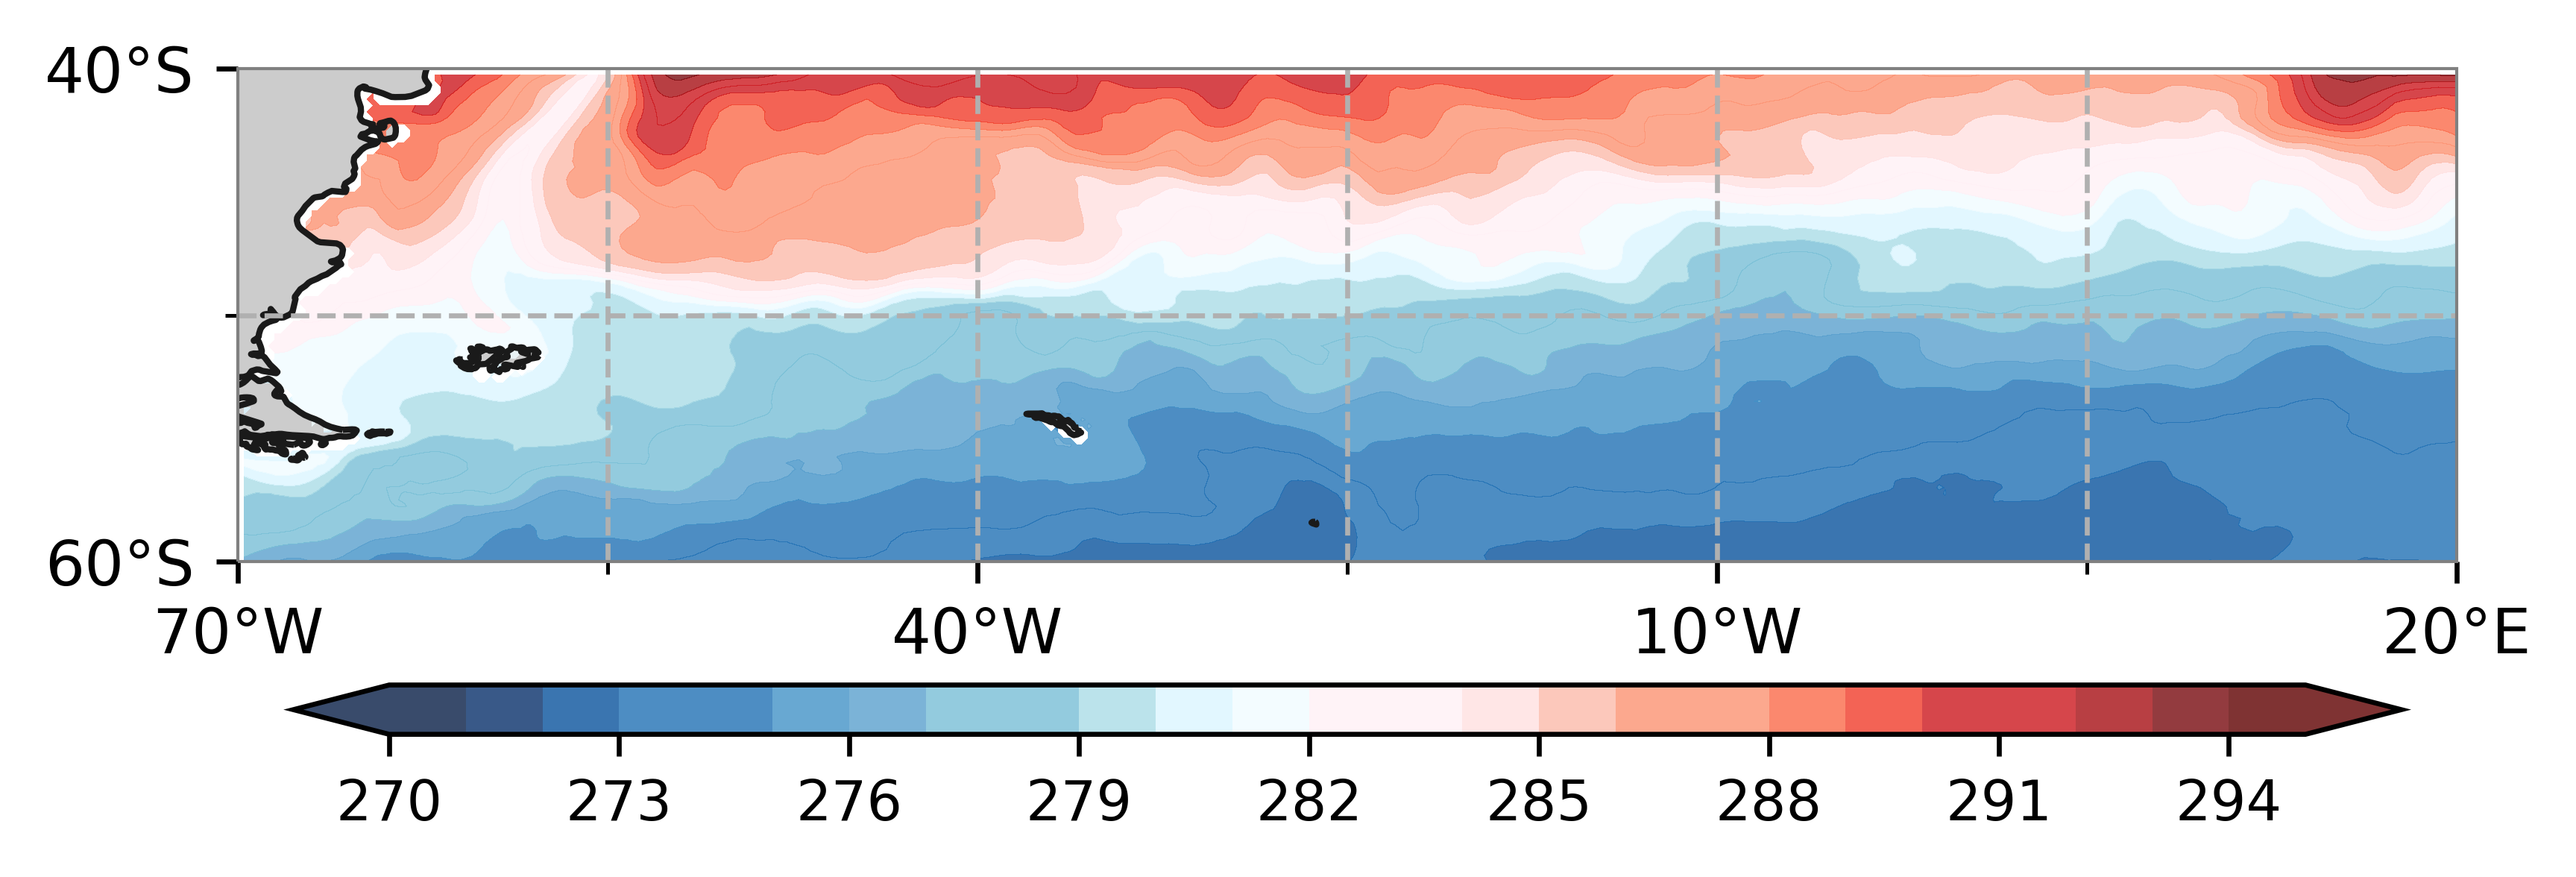

In [4]:
#del plot
from utils import plot
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import cmaps
fig = plt.figure(dpi=600)
proj = ccrs.PlateCarree() #ccrs.Robinson()ccrs.Mollweide()Mollweide()
ax = fig.add_subplot(111, projection=proj)

levels = np.linspace(270, 295, num=26)

data_renamed = data.rename({'x': 'lon', 'y': 'lat'})
plot.one_map_region(data_renamed, ax, cmap=transparent_cmap, levels=levels,  extents=[-70, 20, -60, -40], interval=[30, 20], mask_ocean=False, add_coastlines=True, add_land=True, add_river=False, add_lake=False, add_stock=False, add_gridlines=True, colorbar=True, pad=0.25, plotfunc="contourf")

In [5]:
import xarray as xr
file_name='data/AS_1204_pre3.tif' 
ds=xr.open_dataset(file_name)
data = ds['band_data'][0]

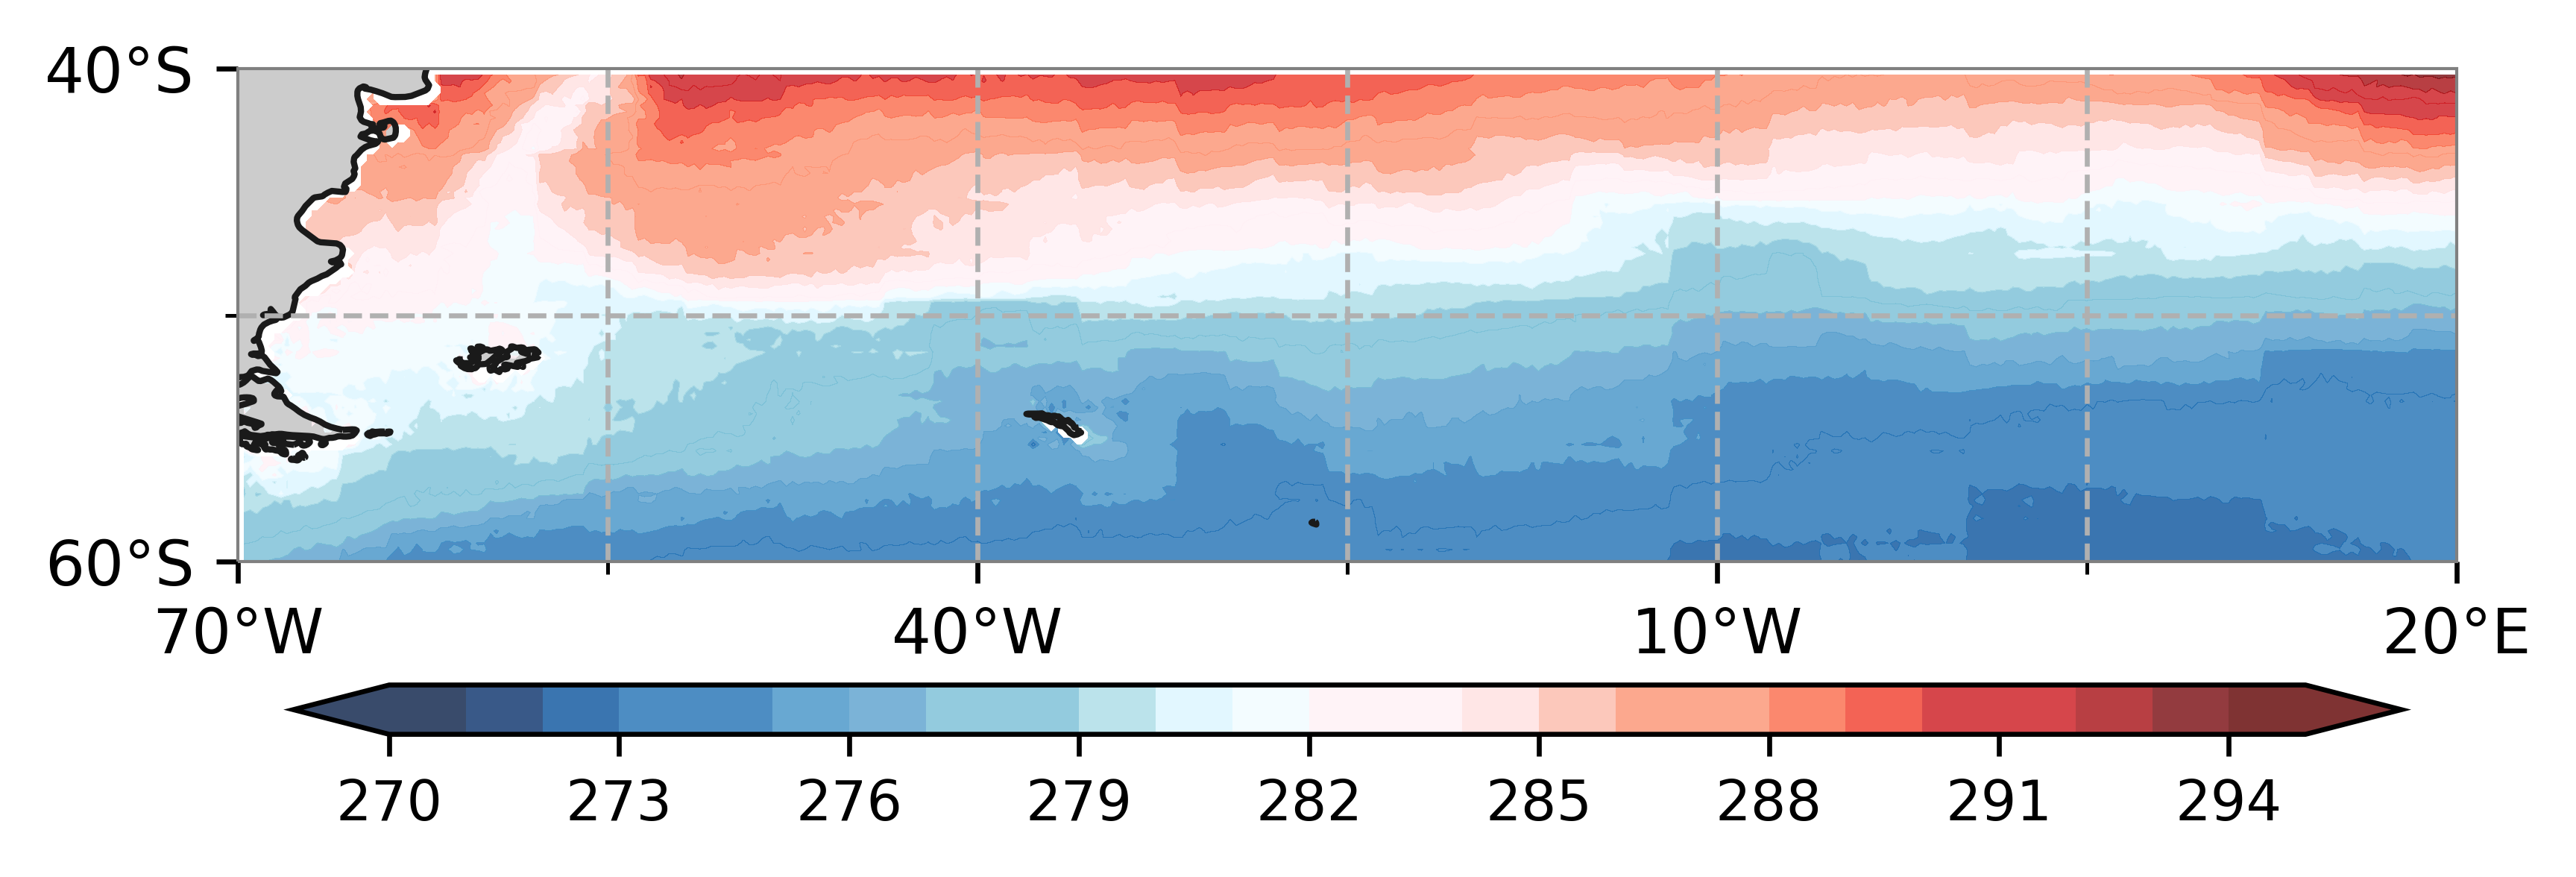

In [6]:
#del plot
from utils import plot
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import cmaps
fig = plt.figure(dpi=600)
proj = ccrs.PlateCarree() #ccrs.Robinson()ccrs.Mollweide()Mollweide()
ax = fig.add_subplot(111, projection=proj)
levels = np.linspace(270, 295, num=26)
data_renamed = data.rename({'x': 'lon', 'y': 'lat'})
plot.one_map_region(data_renamed, ax, cmap=transparent_cmap, levels=levels,  extents=[-70, 20, -60, -40], interval=[30, 20], mask_ocean=False, add_coastlines=True, add_land=True, add_river=False, add_lake=False, add_stock=False, add_gridlines=True, colorbar=True, pad=0.25, plotfunc="contourf")


C:\Users\DELL\AppData\Local\Temp\ipykernel_9476\1527804058.py:37: FutureWarning: Passing `palette` without assigning `hue` is deprecated.
  sns.swarmplot(
d:\miniconda\envs\geo\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
d:\miniconda\envs\geo\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
d:\miniconda\envs\geo\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


Text(29.847222222222214, 0.5, '')

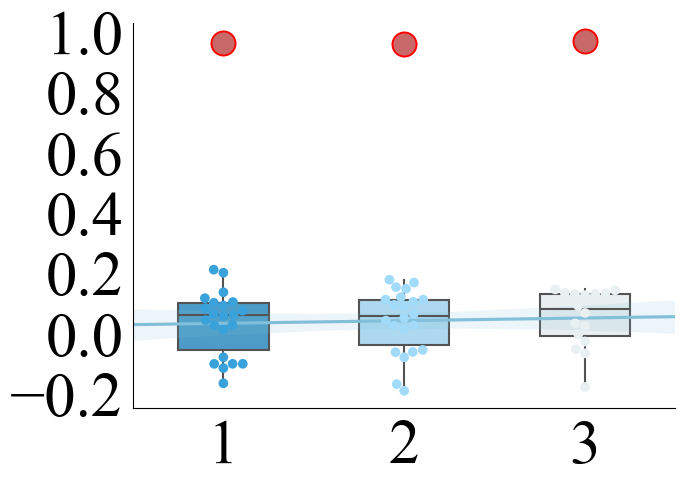

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set up color palette and read data
colors = ['#39A2DB', '#A2DBFA', '#E8F0F2']
data = pd.read_csv('../data/anom_r.csv')

# Filter and process data
r_data = data[(data['Type'] == 'R') & (data['Region'] == 'AO')].copy()
non_ai_data = r_data[(r_data['Model'] != 'AI') & (r_data['Model'] != 'CNN') & (r_data['Model'] != 'Geoformer')].copy()
ai_data = r_data[r_data['Model'] == 'AI'].copy()

# Create mapping for 'Month' to indices
month_order = sorted(data['Month'].unique())
month_mapping = {month: i for i, month in enumerate(month_order)}
non_ai_data['MonthIndex'] = non_ai_data['Month'].map(month_mapping)
ai_data['MonthIndex'] = ai_data['Month'].map(month_mapping)

# Plot setup
plt.figure(figsize=(7, 5))

# Boxplot without outliers
boxplot = sns.boxplot(
    x='Month', y='Value', data=non_ai_data, palette=colors,
    showfliers=False, width=0.5, showcaps=False
)


# Regression line
sns.regplot(
    data=non_ai_data, x="MonthIndex", y="Value",
    scatter=False, truncate=False, order=1, color="#81BFDA"
)

# Add swarm plot
sns.swarmplot(
    data=non_ai_data, x="Month", y="Value", palette=colors, size=7, edgecolor='black'
)

# Highlight AI models with scatter plot
sns.scatterplot(
    x='MonthIndex', y='Value', data=ai_data,
    color='#C96868', s=300, edgecolor='red'
)

# Customize plot: show only left and bottom axes, hide ticks
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['left'].set_visible(True)
plt.gca().spines['bottom'].set_visible(True)
plt.gca().tick_params(left=False, bottom=False, labelsize=14)  # Remove ticks and adjust label size

# Set font to Times New Roman
plt.xticks(fontname='Times New Roman', fontsize=45)
plt.yticks(fontname='Times New Roman', fontsize=45)
plt.xlabel('')  # Remove x-axis label
plt.ylabel('')  # Remove y-axis label




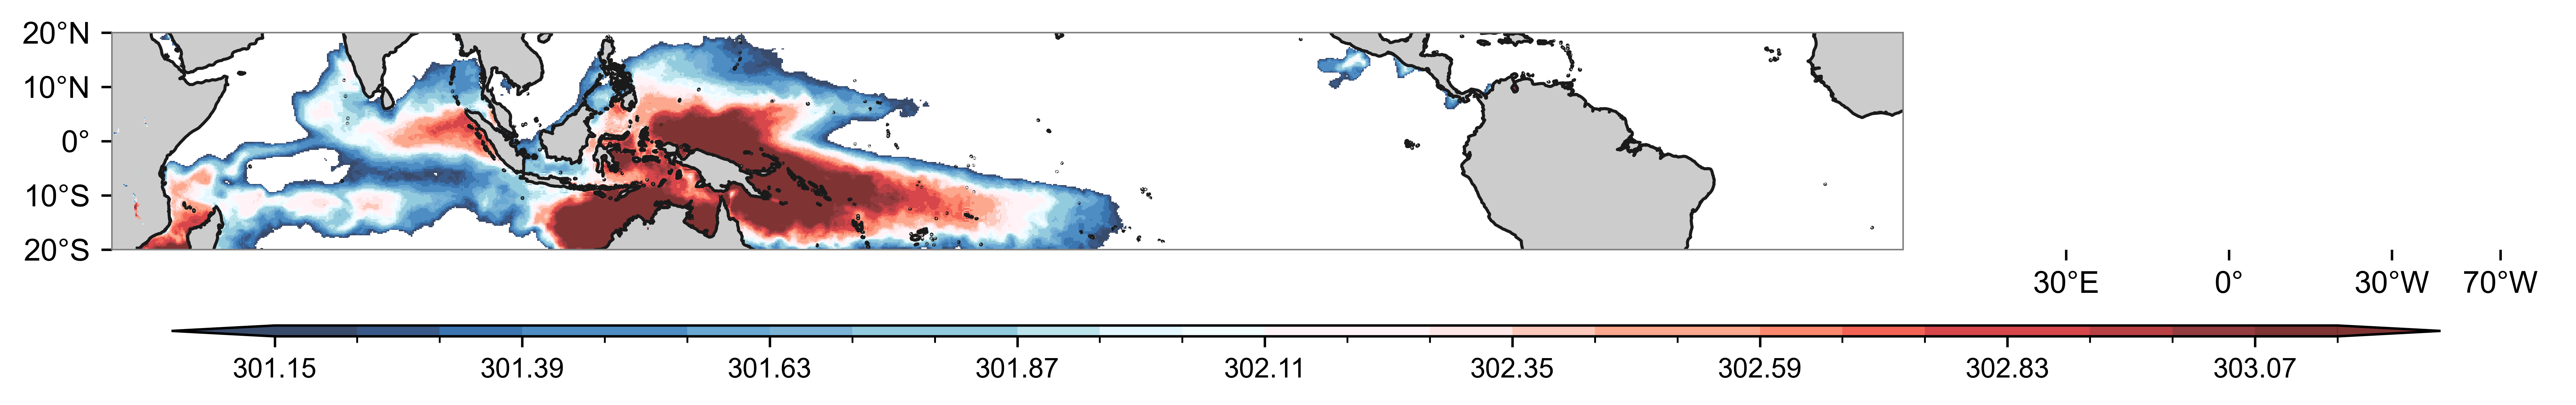

In [ ]:
from matplotlib.colors import ListedColormap
import cmaps
import numpy as np
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter 
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from utils import plot

# 创建透明色图
original_cmap = cmaps.temp_19lev
alpha = 0.8
transparent_cmap = original_cmap(np.arange(original_cmap.N))
transparent_cmap[:, -1] = alpha
transparent_cmap = ListedColormap(transparent_cmap)

# 创建图表
fig = plt.figure(figsize=(14, 5), dpi=600)
ax = fig.add_subplot(111, projection=ccrs.PlateCarree(central_longitude=180))

# 设置数据级别
levels = np.linspace(301.15, 303.15, num=26)

# 绘制数据
plot.one_map_region(ds_subset, ax, cmap=transparent_cmap, levels=levels, mask_ocean=False, 
                    add_coastlines=True, add_land=True, add_river=False, add_lake=False, 
                    add_stock=False, add_gridlines=False, colorbar=True, pad=0.35, 
                    plotfunc="pcolormesh", rasterized=True, transform=ccrs.PlateCarree())

# 设置显示范围：从30°E到70°W
# 在中心经度为180的系统中，30°E是210，70°W是110
ax.set_extent([210, 290, -20, 20], crs=ccrs.PlateCarree(central_longitude=180))

# 设置经度刻度
lon_ticks = [210, 240, 270, 290]  # 30°E, 60°E, 90°E, 110°E (即70°W)
ax.set_xticks(lon_ticks, crs=ccrs.PlateCarree(central_longitude=180))
lon_labels = ['30°E', '0°', '30°W', '70°W']
ax.set_xticklabels(lon_labels)

# 设置纬度刻度
ax.set_yticks(np.arange(-20, 21, 10))
ax.yaxis.set_major_formatter(LatitudeFormatter())
plt.savefig(r'D:\Onedrive\Acdemic\weather\revise\revise2\fig2\WP_2101_obs.svg')



C:\Users\DELL\AppData\Local\Temp\ipykernel_67276\2195024789.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


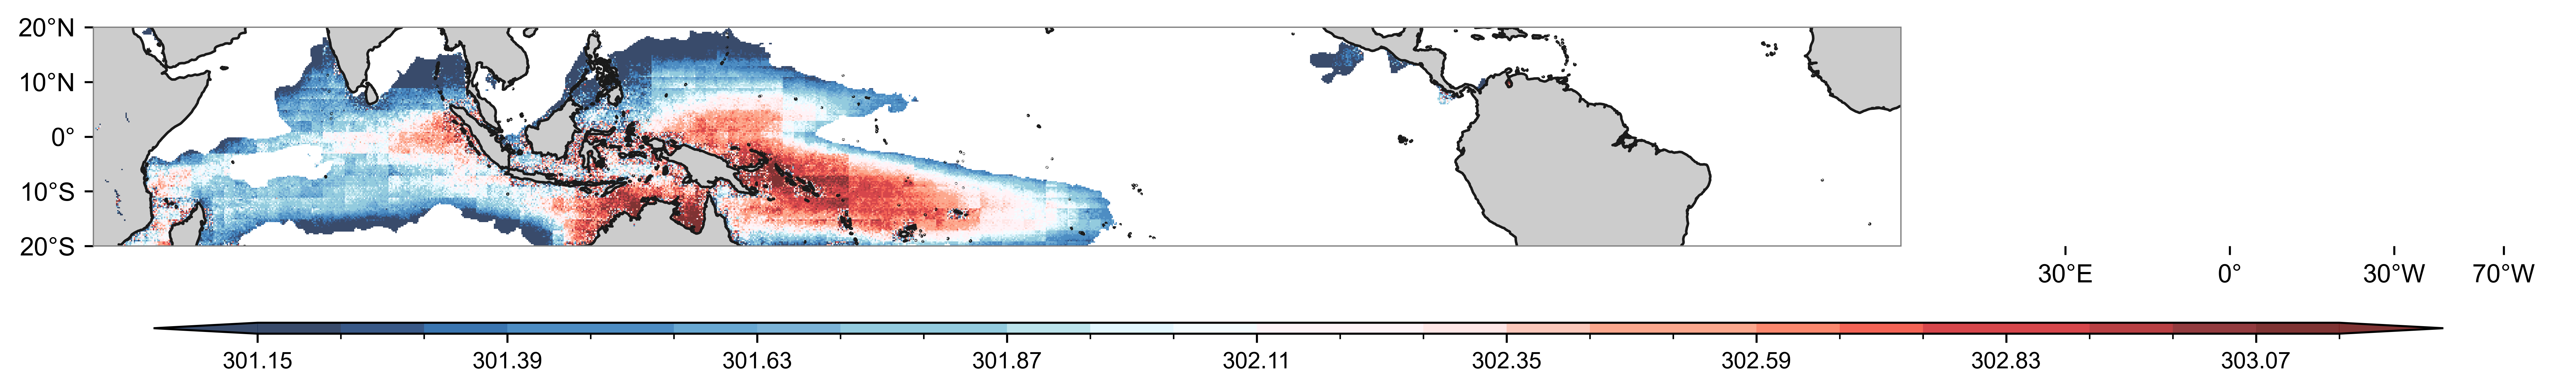

In [ ]:
from matplotlib.colors import ListedColormap
import cmaps
import numpy as np
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter 
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from utils import plot

# 创建透明色图
original_cmap = cmaps.temp_19lev
alpha = 0.8
transparent_cmap = original_cmap(np.arange(original_cmap.N))
transparent_cmap[:, -1] = alpha
transparent_cmap = ListedColormap(transparent_cmap)

# 创建图表
fig = plt.figure(figsize=(14, 5), dpi=600)
ax = fig.add_subplot(111, projection=ccrs.PlateCarree(central_longitude=180))

# 设置数据级别
levels = np.linspace(301.15, 303.15, num=26)

# 绘制数据
plot.one_map_region(ds_subset2, ax, cmap=transparent_cmap, levels=levels, mask_ocean=False, 
                    add_coastlines=True, add_land=True, add_river=False, add_lake=False, 
                    add_stock=False, add_gridlines=False, colorbar=True, pad=0.35, 
                    plotfunc="pcolormesh", rasterized=True, transform=ccrs.PlateCarree())

# 设置显示范围：从30°E到70°W
# 在中心经度为180的系统中，30°E是210，70°W是110
ax.set_extent([210, 290, -20, 20], crs=ccrs.PlateCarree(central_longitude=180))

# 设置经度刻度
lon_ticks = [210, 240, 270, 290]  # 30°E, 60°E, 90°E, 110°E (即70°W)
ax.set_xticks(lon_ticks, crs=ccrs.PlateCarree(central_longitude=180))
lon_labels = ['30°E', '0°', '30°W', '70°W']
ax.set_xticklabels(lon_labels)

# 设置纬度刻度
ax.set_yticks(np.arange(-20, 21, 10))
ax.yaxis.set_major_formatter(LatitudeFormatter())
plt.savefig(r'D:\Onedrive\Acdemic\weather\revise\revise2\fig2\WP_2101_pre.svg')


plt.tight_layout()

In [ ]:
import xarray as xr

# 打开 NetCDF 数据
file_name = 'E:/data/SST/test/SST3_201605_202212_Cang.nc'
ds = xr.open_dataset(file_name)

lat_min, lat_max = -40, -60
lon_min, lon_max = 290, 360  
id = 56
ds1 = ds.obs[id] - monthly_avg_da[(id+4)%12]
ds2 = ds.month1[id] - monthly_avg_da[(id+4)%12]
# 提取目标区域
ds_subset = ds1.sel(lat=slice(lat_min, lat_max), lon=slice(lon_min, lon_max))
ds_subset2 = ds2.sel(lat=slice(lat_min, lat_max), lon=slice(lon_min, lon_max))



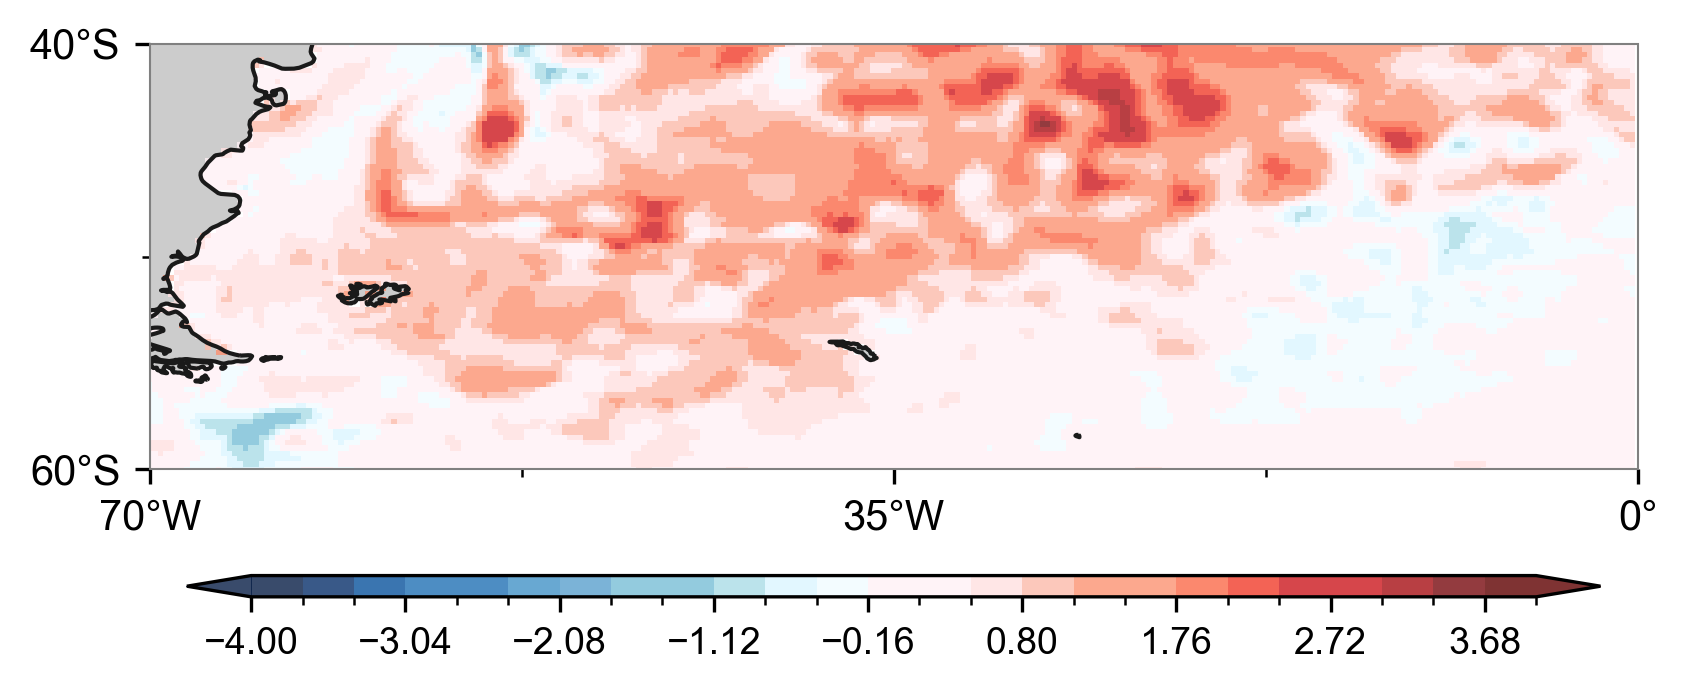

In [ ]:
#del plot
from utils import plot
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import cmaps
fig = plt.figure(dpi=300)
proj = ccrs.PlateCarree() #ccrs.Robinson()ccrs.Mollweide()Mollweide()
ax = fig.add_subplot(111, projection=proj)

levels = np.linspace(-4, 4, num=26)

plot.one_map_region(ds_subset, ax, cmap=transparent_cmap, levels=levels,  extents=[-70, 0, -60, -40], interval=[35, 20], mask_ocean=False, add_coastlines=True, 
                    add_land=True, add_river=False, add_lake=False, add_stock=False, add_gridlines=False, colorbar=True, pad=0.25, plotfunc="pcolormesh", rasterized=True)
plt.savefig(r'D:\Onedrive\Acdemic\weather\revise\revise2\fig2\SAO_2101_obs.svg')

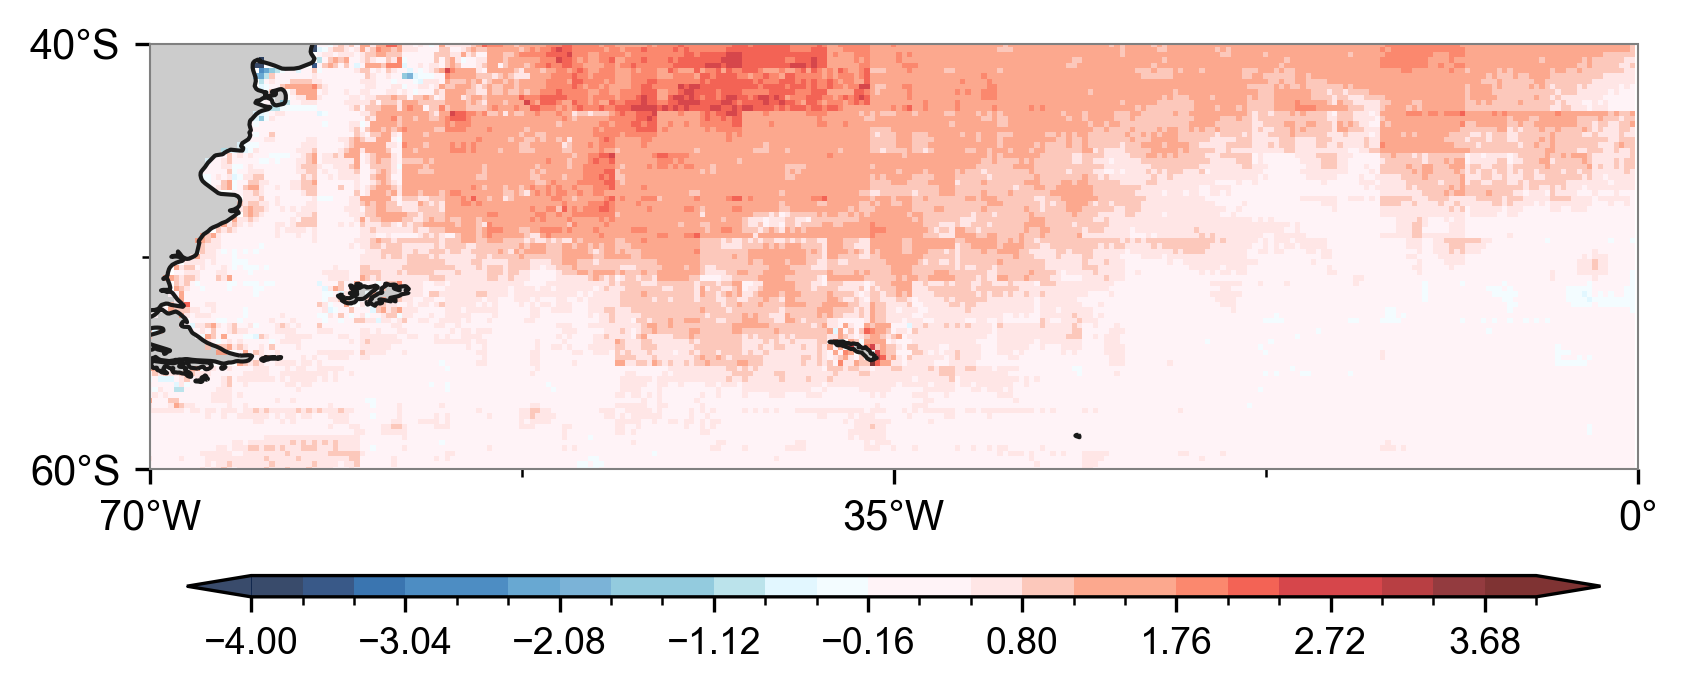

In [ ]:
#del plot
from utils import plot
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import cmaps
fig = plt.figure(dpi=300)
proj = ccrs.PlateCarree() #ccrs.Robinson()ccrs.Mollweide()Mollweide()
ax = fig.add_subplot(111, projection=proj)

levels = np.linspace(-4, 4, num=26)

plot.one_map_region(ds_subset2, ax, cmap=transparent_cmap, levels=levels,  extents=[-70, 0, -60, -40], interval=[35, 20], mask_ocean=False, add_coastlines=True, 
                    add_land=True, add_river=False, add_lake=False, add_stock=False, add_gridlines=False, colorbar=True, pad=0.25, plotfunc="pcolormesh", rasterized=True)
plt.savefig(r'D:\Onedrive\Acdemic\weather\revise\revise2\fig2\SAO_2101_pre.svg')

In [ ]:
# 定义截取区域的纬度和经度范围
lat_min, lat_max = 5, -5
lon_min, lon_max = 190, 240  # 注意 70W 转为 360 度制为 290E
id = 56
ds1 = ds.obs[id] - monthly_avg_da[(id+4)%12]
ds2 = ds.month1[id] - monthly_avg_da[(id+4)%12]
# 提取目标区域
ds_subset = ds1.sel(lat=slice(lat_min, lat_max), lon=slice(lon_min, lon_max))
ds_subset2 = ds2.sel(lat=slice(lat_min, lat_max), lon=slice(lon_min, lon_max))

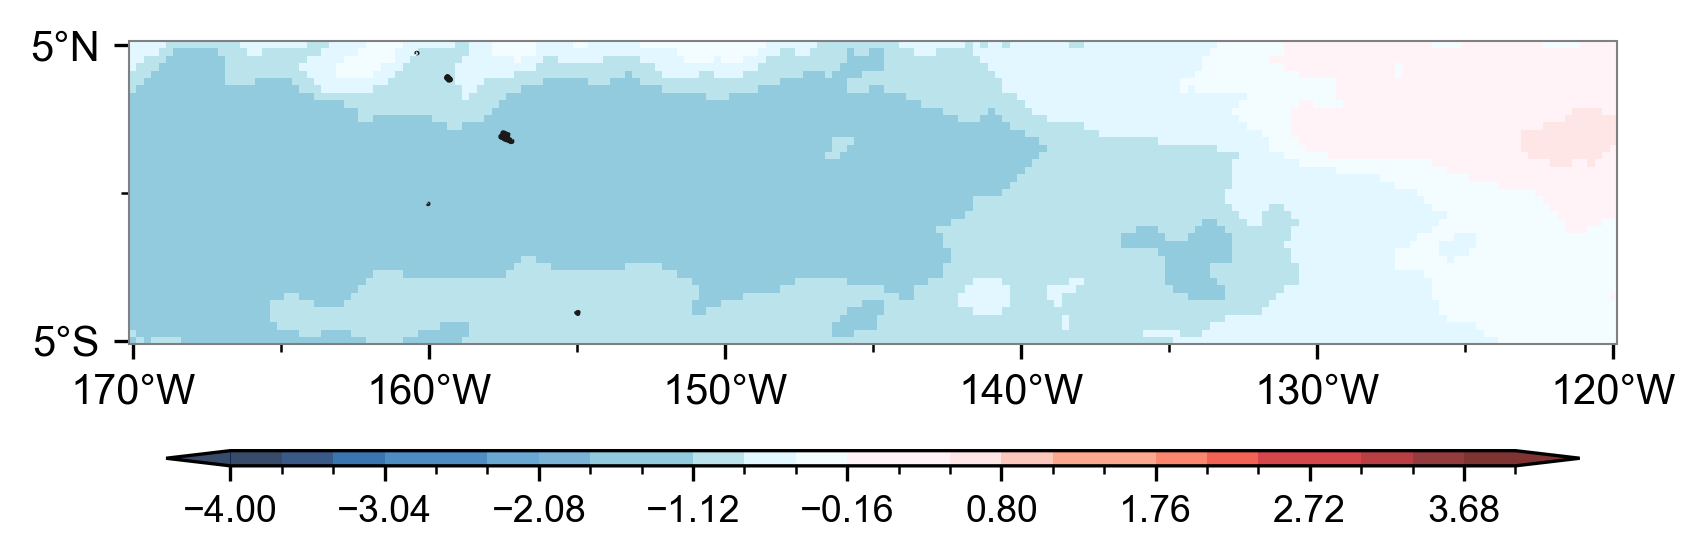

In [ ]:
from matplotlib.colors import ListedColormap
import cmaps
import numpy as np
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter 
original_cmap = cmaps.temp_19lev
alpha = 0.8
transparent_cmap = original_cmap(np.arange(original_cmap.N))
transparent_cmap[:, -1] = alpha
transparent_cmap = ListedColormap(transparent_cmap)
from utils import plot
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

fig = plt.figure(dpi=300)
proj = ccrs.PlateCarree(central_longitude=90)#ccrs.Mollweide()Mollweide()
ax = fig.add_subplot(111, projection=proj)
levels = np.linspace(-4, 4, num=26)

#plot.one_map_region(data_renamed, ax, cmap=transparent_cmap, levels=levels,  mask_ocean=False, add_coastlines=True, add_land=True, add_river=False, add_lake=False, add_stock=False, add_gridlines=False, colorbar=True, pad=0.35, plotfunc="contourf")
plot.one_map_region(ds_subset, ax, cmap=transparent_cmap, levels=levels,   mask_ocean=False, add_coastlines=True, add_land=True, 
                    add_river=False, add_lake=False, add_stock=False, add_gridlines=False, colorbar=True, pad=0.35, plotfunc="pcolormesh", rasterized=True)
ax.set_xticks(list(range(190-90,190+10+50-90,10)))
ax.set_xticks(list(range(190-90,190+5+50-90,5)), minor=True)
ax.set_yticks(np.arange(-5, 5 + 10, 10))
ax.set_yticks(np.arange(-5, 5 + 5, 5), minor=True)
ax.xaxis.set_major_formatter(LongitudeFormatter())
ax.yaxis.set_major_formatter(LatitudeFormatter())

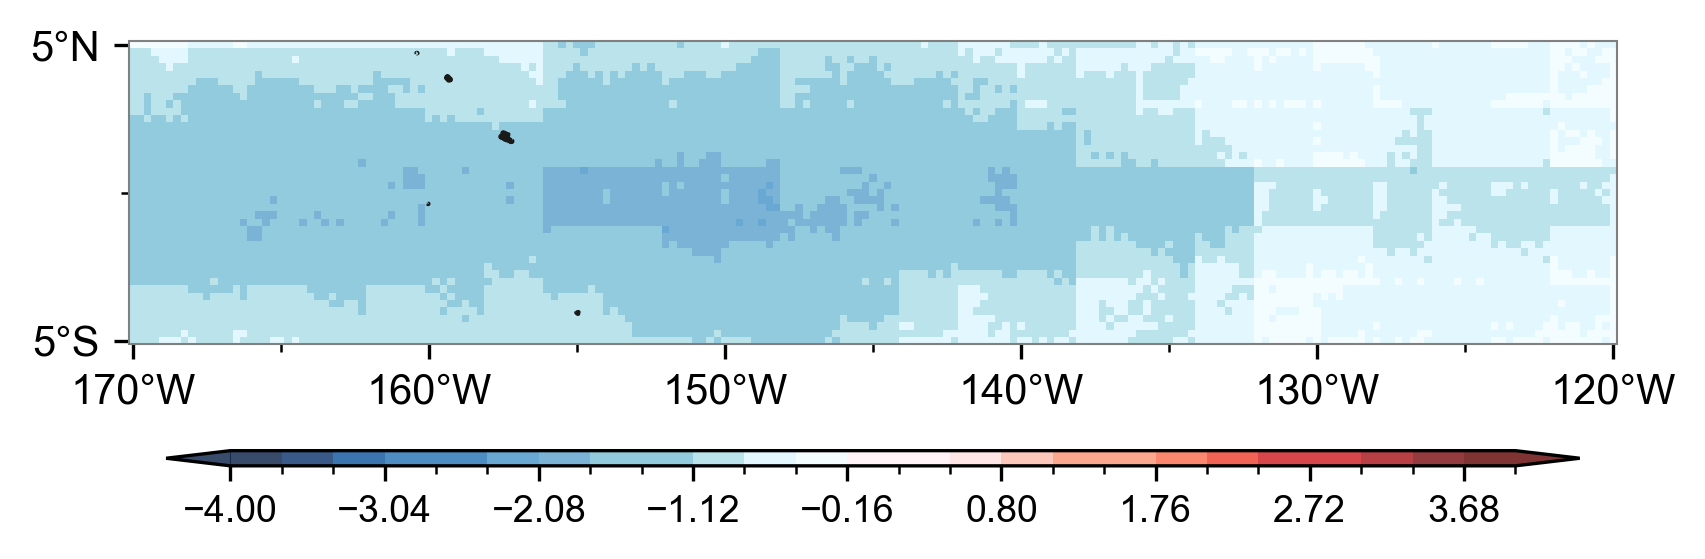

In [ ]:
from matplotlib.colors import ListedColormap
import cmaps
import numpy as np
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter 
original_cmap = cmaps.temp_19lev
alpha = 0.8
transparent_cmap = original_cmap(np.arange(original_cmap.N))
transparent_cmap[:, -1] = alpha
transparent_cmap = ListedColormap(transparent_cmap)
from utils import plot
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

fig = plt.figure(dpi=300)
proj = ccrs.PlateCarree(central_longitude=90)#ccrs.Mollweide()Mollweide()
ax = fig.add_subplot(111, projection=proj)
levels = np.linspace(-4, 4, num=26)

#plot.one_map_region(data_renamed, ax, cmap=transparent_cmap, levels=levels,  mask_ocean=False, add_coastlines=True, add_land=True, add_river=False, add_lake=False, add_stock=False, add_gridlines=False, colorbar=True, pad=0.35, plotfunc="contourf")
plot.one_map_region(ds_subset2, ax, cmap=transparent_cmap, levels=levels,   mask_ocean=False, add_coastlines=True, add_land=True, 
                    add_river=False, add_lake=False, add_stock=False, add_gridlines=False, colorbar=True, pad=0.35, plotfunc="pcolormesh", rasterized=True)
ax.set_xticks(list(range(190-90,190+10+50-90,10)))
ax.set_xticks(list(range(190-90,190+5+50-90,5)), minor=True)
ax.set_yticks(np.arange(-5, 5 + 10, 10))
ax.set_yticks(np.arange(-5, 5 + 5, 5), minor=True)
ax.xaxis.set_major_formatter(LongitudeFormatter())
ax.yaxis.set_major_formatter(LatitudeFormatter())

In [ ]:
import xarray as xr
import numpy as np
ds = xr.open_dataset('E:/data/SST/test/SST3_201605_202212_v2.nc')

ocean_mask = np.load('E:/data/ocean_mask.npy')
monthly_avg_temp = np.load('E:/data/monthly_avg_temp.npy')

months = (ds['time'].values % 100).astype(int) - 1
ds['obs_anomaly'] = ds['obs'] - monthly_avg_temp[months, :, :]
ds['month1_anomaly'] = ds['month1'] - monthly_avg_temp[months, :, :]
ds['month2_anomaly'] = ds['month2'] - monthly_avg_temp[months, :, :]
ds['month3_anomaly'] = ds['month3'] - monthly_avg_temp[months, :, :]

for t in range(ds.sizes['time']):
    ds.obs[t, :, :].values[ocean_mask] = np.nan
    ds.month1[t, :, :].values[ocean_mask] = np.nan
    ds.month2[t, :, :].values[ocean_mask] = np.nan
    ds.month3[t, :, :].values[ocean_mask] = np.nan
    ds.obs_anomaly[t, :, :].values[ocean_mask] = np.nan
    ds.month1_anomaly[t, :, :].values[ocean_mask] = np.nan
    ds.month2_anomaly[t, :, :].values[ocean_mask] = np.nan
    ds.month3_anomaly[t, :, :].values[ocean_mask] = np.nan

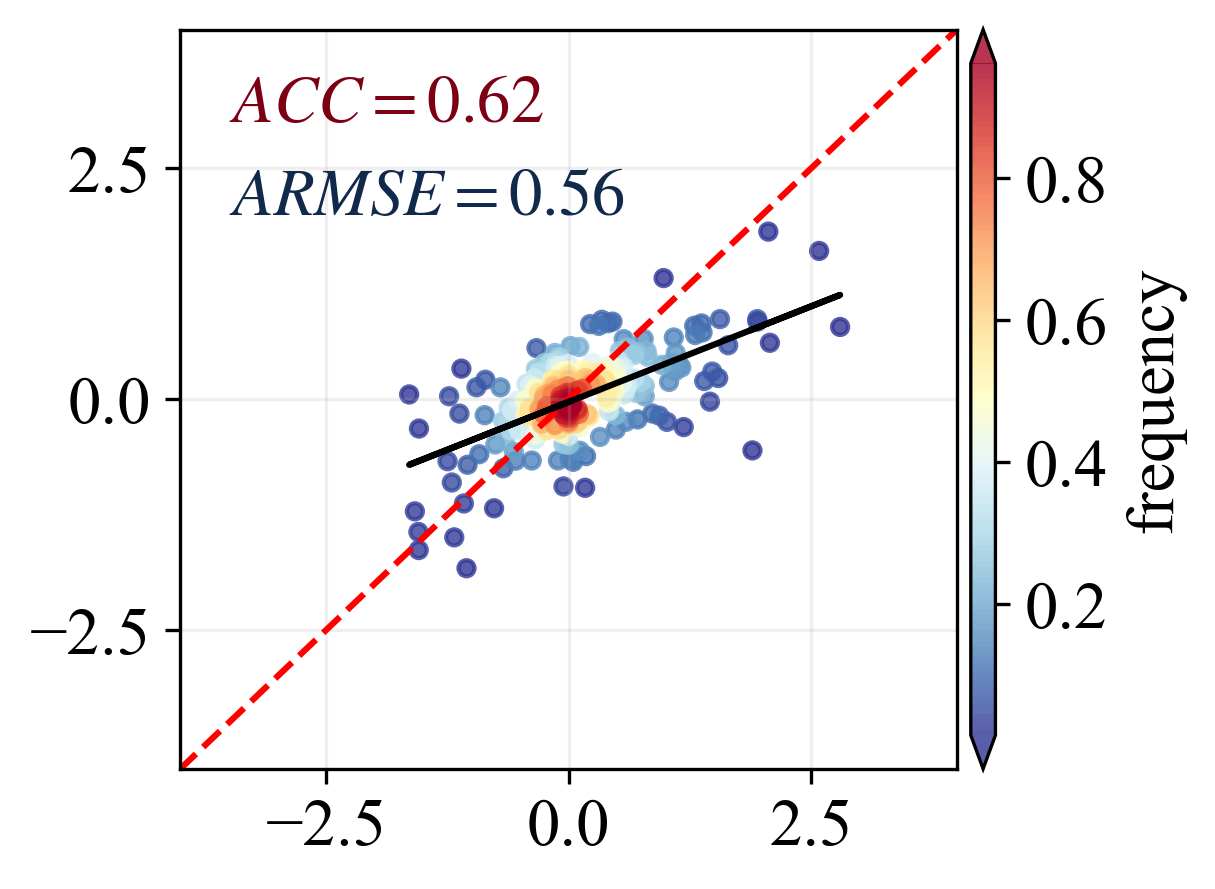

In [ ]:
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from matplotlib import rcParams
from statistics import mean
from sklearn.metrics import explained_variance_score,r2_score,median_absolute_error,mean_squared_error,mean_absolute_error
from scipy.stats import pearsonr
import cmaps
from matplotlib.ticker import MultipleLocator


np.random.seed(607)

id = 56
ssta2 = ds.obs_anomaly[id].values  # True values
ssta1 = ds.month1_anomaly[id].values  # Predicted values

# Get indices of non-NaN points
valid_points = np.where(~np.isnan(ssta1) & ~np.isnan(ssta2))
valid_indices = list(zip(valid_points[0], valid_points[1]))

# Get indices within latitude range -60 to 60 (indices 180 to 540 in 721 grid)
lat_mask = [(i,j) for i,j in valid_indices if 0 <= i <= 721]
selected_indices = np.random.choice(len(lat_mask), size=240, replace=False)
selected_points = [valid_indices[i] for i in selected_indices]

# Create arrays with just the selected points
ssta1 = np.array([ssta1[i,j] for i,j in selected_points])
ssta2 = np.array([ssta2[i,j] for i,j in selected_points])

x = ssta2[~np.isnan(ssta2)].flatten()
y = ssta1[~np.isnan(ssta1)].flatten()
df = pd.DataFrame({
    'obs': x,
    'pre': y
})

# Set plot style
config = {"font.family":'Times New Roman',"font.size": 16,"mathtext.fontset":'stix'}
rcParams.update(config)

# Calculate metrics
x = df['obs']; y = df['pre']

BIAS = mean(x - y)
MSE = mean_squared_error(x, y)
RMSE = np.power(MSE, 0.5)
R2 = pearsonr(x, y)[0]
adjR2 = 1-((1-r2_score(x,y))*(len(x)-1))/(len(x)-5-1)
MAE = mean_absolute_error(x, y)
EV = explained_variance_score(x, y)
NSE = 1 - (RMSE ** 2 / np.var(x))

# Calculate point density
xy = np.vstack([x, y])
z = stats.gaussian_kde(xy)(xy)
idx = z.argsort()
x, y, z = x.iloc[idx], y.iloc[idx], z[idx] 

# Fit least squares regression line
def slope(xs, ys):
    m = (((mean(xs) * mean(ys)) - mean(xs * ys)) / ((mean(xs) * mean(xs)) - mean(xs * xs)))
    b = mean(ys) - m * mean(xs)
    return m, b
k, b = slope(x, y)
regression_line = []
for a in x:
    regression_line.append((k * a) + b)
slope, intercept = np.polyfit(x, regression_line, 1)
n = 1

# Create plot
fig, ax = plt.subplots(figsize=(4, 3.2), dpi=300)
scatter = ax.scatter(x, y, marker='o', c=z, edgecolors=None, s=15, cmap=cmaps.MPL_RdYlBu_r,  alpha=0.8)
cbar = plt.colorbar(scatter, shrink=1, orientation='vertical', extend='both', pad=0.015, aspect=30, label='frequency')
plt.plot([-5, 5], [-5, 5], 'red', lw=1.5, linestyle='--', label='1:1 line')
plt.plot(x, regression_line, 'black', lw=1.5, label='Regression Line')
ax.grid(True, linestyle='-', alpha=0.2)
ax.xaxis.set_major_locator(MultipleLocator(2.5))
ax.yaxis.set_major_locator(MultipleLocator(2.5))

plt.text(-3.5,3, '$ACC=%.2f$' % R2, family = 'Times New Roman', horizontalalignment='left', color='#7c0014')
plt.text(-3.5,2, '$ARMSE=%.2f$' % RMSE, family = 'Times New Roman', horizontalalignment='left', color='#11294b')

plt.axis([-4, 4, -4, 4])
plt.savefig('D:/Onedrive/Acdemic/weather/revise/fig0/ssta_scatter.svg', format="svg", dpi=300, bbox_inches = 'tight')

d:\Onedrive\Acdemic\weather\code\utils\plot.py:1097: RuntimeWarning: Mean of empty slice
  MED = np.nanmean(da.values, axis=1)
d:\miniconda\envs\torch\lib\site-packages\numpy\lib\nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
d:\Onedrive\Acdemic\weather\code\utils\plot.py:1100: RuntimeWarning: divide by zero encountered in true_divide
  margin_of_error = 1.96 * (STD / np.sqrt(n))


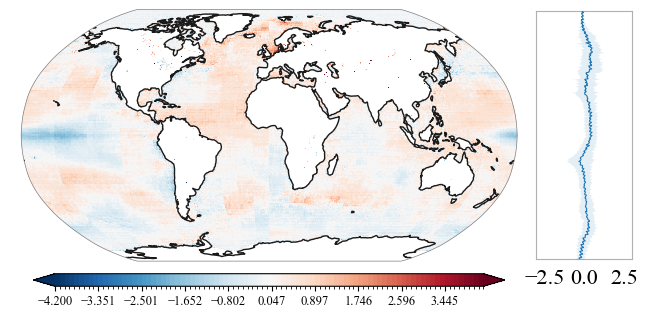

In [ ]:
from utils import plot
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import xarray as xr
data_xr = ds.month1_anomaly[id]

# 设置更大的图像尺寸和边距
fig = plt.figure()
proj = ccrs.Robinson()
ax = fig.add_subplot(111, projection=proj)
levels = np.linspace(-4.2, 4.2, num=90)
plot.one_map_flat(data_xr, ax, levels=levels, cmap="RdBu_r", mask_ocean=False, add_coastlines=True, add_land=False, colorbar=True, plotfunc="pcolormesh")

# 调整统计图的位置，向左移动
ax2 = fig.add_axes([0.93, 0.237, 0.15, 0.517])
plot.add_sta(ax2, data_xr, [-3,3], 'lat')

# 调整布局并保存
plt.savefig(r'D:\Onedrive\Acdemic\weather\revise\fig0\sst_pre.svg', dpi=600, bbox_inches='tight')

d:\Onedrive\Acdemic\weather\code\utils\plot.py:1097: RuntimeWarning: Mean of empty slice
  MED = np.nanmean(da.values, axis=1)
d:\miniconda\envs\torch\lib\site-packages\numpy\lib\nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


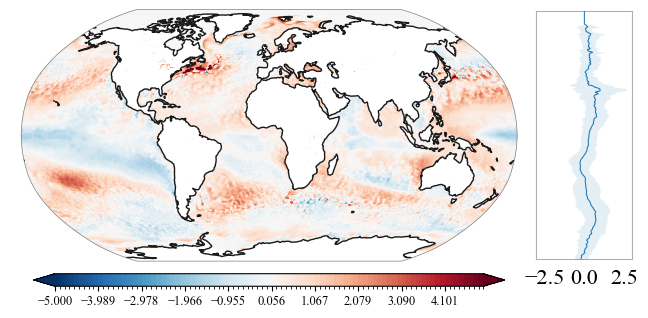

In [ ]:
from utils import plot
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import xarray as xr
data_xr = ds.obs_anomaly[id]

fig = plt.figure()
proj = ccrs.Robinson() #ccrs.Robinson()ccrs.Mollweide()Mollweide()
ax = fig.add_subplot(111, projection=proj)
levels = np.linspace(-5, 5, num=90)
plot.one_map_flat(data_xr, ax, levels=levels, cmap="RdBu_r",  mask_ocean=False, add_coastlines=True, add_land=False,  colorbar=True, plotfunc="pcolormesh")
ax2 = fig.add_axes([0.93, 0.237, 0.15, 0.517])
plot.add_sta(ax2, data_xr, [-3,3], 'lat')
plt.savefig(r'D:\Onedrive\Acdemic\weather\revise\fig0\sst_obs.svg', dpi=600, bbox_inches='tight')

Correlation coefficient between ensemble mean and observations: 0.7888
p-value: 3.7076e-18


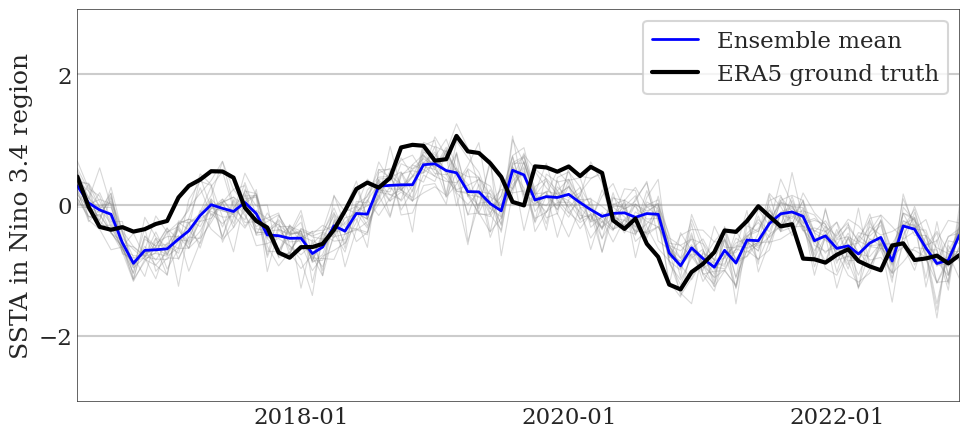

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
from scipy.stats import pearsonr
import pandas as pd
import numpy as np
import matplotlib

plt.rcParams['font.size'] = 45
plt.rcParams['font.family'] = 'serif'
plt.rcParams['ytick.direction'] = 'out'
plt.rcParams['ytick.minor.visible'] = True
plt.rcParams['ytick.major.right'] = True
plt.rcParams['ytick.right'] = True
plt.rcParams['xtick.bottom'] = True

matplotlib.rcParams['font.size']=12
matplotlib.rcParams['axes.linewidth']=0.5

fig = plt.figure(figsize=(9, 4))
ax = fig.add_subplot(111)

date = pd.to_datetime(ds['time'].values, format='%Y%m')

# Plot ensemble members in gray
for i in range(20):
    plt.plot(date, df[f'ensemble{i+1}'], color='gray', alpha=0.3, lw=0.8)

# Calculate and plot ensemble mean
ensemble_columns = [f'ensemble{i+1}' for i in range(20)]
ensemble_mean = df[ensemble_columns].mean(axis=1)
plt.plot(date, ensemble_mean, color='blue', lw=2, label='Ensemble mean')

# Plot observations in black
plt.plot(date, df['obs'], color='black', lw=3, label='ERA5 ground truth')

# Calculate correlation coefficient between ensemble mean and observations
correlation, p_value = pearsonr(ensemble_mean, df['obs'])
print(f"Correlation coefficient between ensemble mean and observations: {correlation:.4f}")
print(f"p-value: {p_value:.4e}")

ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.yaxis.set_major_locator(ticker.MultipleLocator(2))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(2))
ax.minorticks_off()
ax.tick_params(axis='both', which='both', length=0)
ax.xaxis.set_ticks_position('both')
ax.tick_params(width=0.5)
ax.grid(True, axis='y')
xmin, xmax = date.min(), date.max()
ymin, ymax = -3, 3
plt.xlim(xmin, xmax)
plt.ylim(ymin, ymax)

plt.ylabel('SSTA in Nino 3.4 region')
plt.legend()

plt.savefig(r'D:\Onedrive\Acdemic\weather\revise\sm\ensemble\Nino_ensemble.svg', dpi=1000)

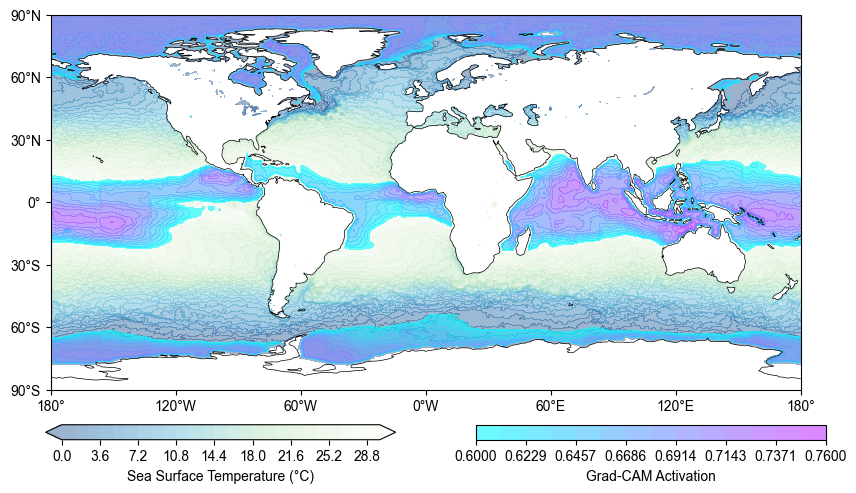

In [ ]:
import xarray as xr
from matplotlib.colors import ListedColormap
import cmaps
import numpy as np
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter 
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from utils import plot
import matplotlib as mpl
from matplotlib import cm
from scipy.ndimage import gaussian_filter
plt.rcParams['font.family'] = "Arial"
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['svg.hashsalt'] = 'hello'

# 加载海温数据
ds = xr.open_dataset('I:/ERA5/surface/sea_surface_temperature/ERA5_20180410.nc')
ds = ds.sst[0].rename({'latitude': 'lat', 'longitude': 'lon'}) - 273.15
lat = np.linspace(90, -90, 721)
lon = np.linspace(0, 359.75, 1440)

# 创建图形
fig = plt.figure(figsize=(10, 5))
proj = ccrs.PlateCarree()
ax = fig.add_subplot(111, projection=proj)

threshold = 0.6
max_thre = 0.8

# 绘制海温图
levels = np.linspace(0, 30, num=26)
sst_data = ds.values
cs = ax.contourf(lon, lat, sst_data, levels=levels, 
                transform=ccrs.PlateCarree(),
                cmap=cmaps.MPL_GnBu_r, extend='both', alpha=0.4)

# 处理GRad-CAM数据
# 归一化到0-1之间
cam_2d_norm = cam_2d - np.min(cam_2d)
cam_2d_norm = cam_2d_norm / np.max(cam_2d_norm) if np.max(cam_2d_norm) > 0 else cam_2d_norm

# 使用高斯滤波平滑数据
smooth_cam_2d_norm = gaussian_filter(cam_2d_norm, sigma=[2.5, 2.5])

# 设置阈值掩码：仅显示大于阈值的值
mask = smooth_cam_2d_norm > threshold

# 将低于阈值的区域设为nan
masked_data = np.where(mask, smooth_cam_2d_norm, np.nan)

# 创建一个新的norm对象，使threshold-0.8的范围映射到0-1
norm = mpl.colors.Normalize(vmin=threshold, vmax=max_thre)

# 使用pcolormesh显示热图
cmap = cmaps.MPL_cool
cmap.set_bad(alpha=0)  # 设置nan值为透明

# 确保cam_2d的形状与经纬度网格匹配
cam_lon = np.linspace(0, 360, cam_2d.shape[1])
cam_lat = np.linspace(90, -90, cam_2d.shape[0])

# 在同一个图上叠加GRad-CAM
mesh = ax.contourf(cam_lon, cam_lat, masked_data, levels = np.linspace(threshold, max_thre-0.04, num=15),
                    transform=ccrs.PlateCarree(),
                    cmap=cmap, norm=norm, alpha=0.6)

# 添加海温的颜色条
cbar_ax1 = fig.add_axes([0.12, 0.1, 0.35, 0.03])
cbar1 = plt.colorbar(cs, cax=cbar_ax1, orientation='horizontal')
cbar1.set_label('Sea Surface Temperature (°C)')

# 添加GRad-CAM的颜色条
cbar_ax2 = fig.add_axes([0.55, 0.1, 0.35, 0.03])
cbar2 = plt.colorbar(mesh, cax=cbar_ax2, orientation='horizontal')
cbar2.set_label(f'Grad-CAM Activation')

# 添加海岸线
ax.coastlines(linewidth=0.5)
ax.set_global()


# 设置坐标轴格式
ax.set_xticks(np.arange(-180, 181, 60), crs=ccrs.PlateCarree())
ax.set_yticks(np.arange(-90, 91, 30), crs=ccrs.PlateCarree())
lon_formatter = LongitudeFormatter(zero_direction_label=True)
lat_formatter = LatitudeFormatter()
ax.xaxis.set_major_formatter(lon_formatter)
ax.yaxis.set_major_formatter(lat_formatter)

plt.subplots_adjust(left=0.05, right=0.95, bottom=0.2, top=0.95)
plt.savefig('../revise/revise2/sm/grad_cam/cnn.png', dpi=600, bbox_inches='tight')
plt.show()

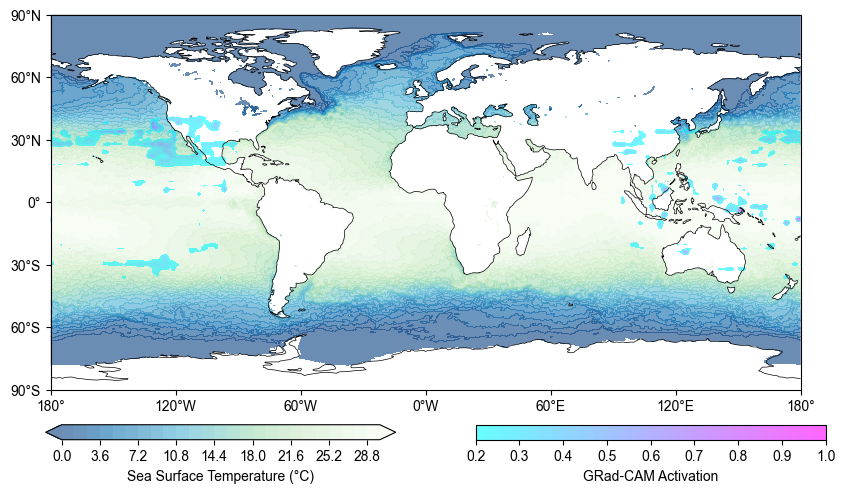

In [ ]:
import xarray as xr
from matplotlib.colors import ListedColormap
import cmaps
import numpy as np
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter 
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from utils import plot
import matplotlib as mpl
from matplotlib import cm
import cmaps

# 加载海温数据
ds = xr.open_dataset('I:/ERA5/surface/sea_surface_temperature/ERA5_20180410.nc')
ds = ds.sst[0].rename({'latitude': 'lat', 'longitude': 'lon'}) - 273.15
lat = np.linspace(90, -90, 721)
lon = np.linspace(0, 359.75, 1440)
cam_2d = result
threshold = 0.2
max_thre = 1.0
# 创建图形
fig = plt.figure(figsize=(10, 5))
proj = ccrs.PlateCarree()
ax = fig.add_subplot(111, projection=proj)

# 绘制海温图
levels = np.linspace(0, 30, num=26)
sst_data = ds.values
cs = ax.contourf(lon, lat, sst_data, levels=levels, 
                transform=ccrs.PlateCarree(),
                cmap=cmaps.MPL_GnBu_r, extend='both', alpha=0.6)

# 处理GRad-CAM数据
# 归一化到0-1之间
cam_2d_norm = cam_2d - np.min(cam_2d)
cam_2d_norm = cam_2d_norm / np.max(cam_2d_norm) if np.max(cam_2d_norm) > 0 else cam_2d_norm

# 设置阈值掩码：仅显示大于阈值的值

mask = cam_2d_norm > threshold

# 将低于阈值的区域设为nan
masked_data = np.where(mask, cam_2d_norm, np.nan)

# 创建一个新的norm对象，使threshold-0.8的范围映射到0-1
norm = mpl.colors.Normalize(vmin=threshold, vmax=max_thre)

# 使用pcolormesh显示热图
cmap = cmaps.MPL_cool#plt.cm.jet
cmap.set_bad(alpha=0)  # 设置nan值为透明

# 确保cam_2d的形状与经纬度网格匹配
cam_lon = np.linspace(0, 360, cam_2d.shape[1])
cam_lat = np.linspace(90, -90, cam_2d.shape[0])

# 在同一个图上叠加GRad-CAM
mesh = ax.pcolormesh(cam_lon, cam_lat, masked_data, 
                    transform=ccrs.PlateCarree(),
                    cmap=cmap, norm=norm, alpha=0.6)

# 添加海温的颜色条
cbar_ax1 = fig.add_axes([0.12, 0.1, 0.35, 0.03])
cbar1 = plt.colorbar(cs, cax=cbar_ax1, orientation='horizontal')
cbar1.set_label('Sea Surface Temperature (°C)')

# 添加GRad-CAM的颜色条
cbar_ax2 = fig.add_axes([0.55, 0.1, 0.35, 0.03])
cbar2 = plt.colorbar(mesh, cax=cbar_ax2, orientation='horizontal')
cbar2.set_label(f'GRad-CAM Activation')

# 添加海岸线
ax.coastlines(linewidth=0.5)
ax.set_global()


# 设置坐标轴格式
ax.set_xticks(np.arange(-180, 181, 60), crs=ccrs.PlateCarree())
ax.set_yticks(np.arange(-90, 91, 30), crs=ccrs.PlateCarree())
lon_formatter = LongitudeFormatter(zero_direction_label=True)
lat_formatter = LatitudeFormatter()
ax.xaxis.set_major_formatter(lon_formatter)
ax.yaxis.set_major_formatter(lat_formatter)

plt.subplots_adjust(left=0.05, right=0.95, bottom=0.2, top=0.95)
plt.savefig('../revise/revise2/sm/grad_cam/atten.png', dpi=600, bbox_inches='tight')
plt.show()

Processing region: AO


Processing E:/data/SST/test/SST_ensemble20_ocean_mask.nc: 100%|██████████| 2/2 [00:00<00:00, 19.40it/s]
Processing E:/data/SST/test/Cansips_ensemble5_ocean_mask.nc: 100%|██████████| 2/2 [00:00<00:00, 75.07it/s]
Processing E:/data/SST/test/FuxiS2S_ensemble51_ocean_mask.nc: 100%|██████████| 2/2 [00:00<00:00, 153.74it/s]
d:\miniconda\envs\geo\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
d:\miniconda\envs\geo\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
d:\miniconda\envs\geo\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a lengt

Processing region: WP


Processing E:/data/SST/test/SST_ensemble20_ocean_mask.nc: 100%|██████████| 2/2 [00:00<00:00, 12.48it/s]
Processing E:/data/SST/test/Cansips_ensemble5_ocean_mask.nc: 100%|██████████| 2/2 [00:00<00:00, 12.73it/s]
Processing E:/data/SST/test/FuxiS2S_ensemble51_ocean_mask.nc: 100%|██████████| 2/2 [00:00<00:00, 32.63it/s]
d:\miniconda\envs\geo\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
d:\miniconda\envs\geo\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
d:\miniconda\envs\geo\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length

Processing region: Nino


...

Processing E:/data/SST/test/SST_ensemble20_ocean_mask.nc: 100%|██████████| 2/2 [00:00<00:00, 43.14it/s]
Processing E:/data/SST/test/Cansips_ensemble5_ocean_mask.nc: 100%|██████████| 2/2 [00:00<00:00, 42.76it/s]
Processing E:/data/SST/test/FuxiS2S_ensemble51_ocean_mask.nc: 100%|██████████| 2/2 [00:00<00:00, 88.37it/s]
d:\miniconda\envs\geo\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
d:\miniconda\envs\geo\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
d:\miniconda\envs\geo\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length

Processing region: SPO


Processing E:/data/SST/test/SST_ensemble20_ocean_mask.nc: 100%|██████████| 2/2 [00:00<00:00, 48.68it/s]
Processing E:/data/SST/test/Cansips_ensemble5_ocean_mask.nc: 100%|██████████| 2/2 [00:00<00:00, 48.12it/s]
Processing E:/data/SST/test/FuxiS2S_ensemble51_ocean_mask.nc: 100%|██████████| 2/2 [00:00<00:00, 95.26it/s]
d:\miniconda\envs\geo\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
d:\miniconda\envs\geo\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
d:\miniconda\envs\geo\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length

Processing region: SAO


Processing E:/data/SST/test/SST_ensemble20_ocean_mask.nc: 100%|██████████| 2/2 [00:00<00:00, 83.03it/s]
Processing E:/data/SST/test/Cansips_ensemble5_ocean_mask.nc: 100%|██████████| 2/2 [00:00<00:00, 86.72it/s]
Processing E:/data/SST/test/FuxiS2S_ensemble51_ocean_mask.nc: 100%|██████████| 2/2 [00:00<00:00, 166.61it/s]
d:\miniconda\envs\geo\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
d:\miniconda\envs\geo\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
d:\miniconda\envs\geo\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a lengt

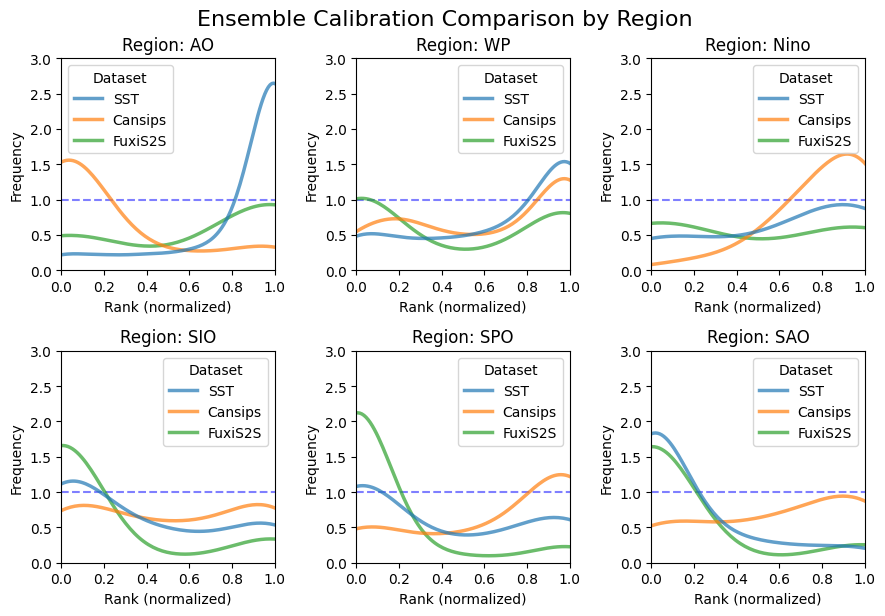

In [ ]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pandas as pd
import matplotlib as mpl

mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['svg.hashsalt'] = 'hello'

# Function to calculate normalized ranks for a specific region
def calculate_normalized_ranks(dataset_path, ensemble_name_pattern, ensemble_count, region_slice, coarse_factor=None):
    # Open dataset
    ds = xr.open_dataset(dataset_path)

    # Apply coarsening if specified
    if coarse_factor is not None:
        ds = ds.coarsen(lat=coarse_factor, lon=coarse_factor, boundary='trim').mean()
    
    # Extract observation and ensemble members
    obs = ds['obs']
    
    if ensemble_name_pattern == 'custom':
        # For Cansips which has custom variable names
        ensembles = [ds[var] for var in [var for var in ds.data_vars if var != 'obs']]
    else:
        # For datasets with ensemble1, ensemble2, etc. naming convention
        ensembles = [ds[f'{ensemble_name_pattern}{i}'] for i in range(1, ensemble_count + 1)]
    
    # Apply region slice - using integer indices for slices
    lat_slice, lon_slice = region_slice
    # Convert slice objects to ensure they use integers
    if isinstance(lat_slice, slice):
        lat_start = int(lat_slice.start) if lat_slice.start is not None else None
        lat_stop = int(lat_slice.stop) if lat_slice.stop is not None else None
        lat_step = int(lat_slice.step) if lat_slice.step is not None else None
        lat_slice = slice(lat_start, lat_stop, lat_step)
    
    if isinstance(lon_slice, slice):
        lon_start = int(lon_slice.start) if lon_slice.start is not None else None
        lon_stop = int(lon_slice.stop) if lon_slice.stop is not None else None
        lon_step = int(lon_slice.step) if lon_slice.step is not None else None
        lon_slice = slice(lon_start, lon_stop, lon_step)
    
    obs = obs.isel(lat=lat_slice, lon=lon_slice)
    ensembles = [ensemble.isel(lat=lat_slice, lon=lon_slice) for ensemble in ensembles]
    
    # Create array to store ranks
    all_ranks = np.array([])
    
    # Process all time steps
    for t in tqdm(range(2), desc=f"Processing {dataset_path}"):
        # Extract current time step data
        obs_time = obs[t].values.flatten()
        ensemble_values = [ensemble[t].values.flatten() for ensemble in ensembles]
        
        # Remove NaN values
        valid_indices = ~np.isnan(obs_time)
        obs_time = obs_time[valid_indices]
        ensemble_values = [e[valid_indices] for e in ensemble_values]
        
        # Calculate rank for each valid grid point
        for i in range(len(obs_time)):
            obs_point = obs_time[i]
            ensemble_points = [e[i] for e in ensemble_values]
            
            # Add observation to ensemble and sort
            combined = np.append(ensemble_points, obs_point)
            sorted_indices = np.argsort(combined)
            
            # Find rank of observation (position in sorted array)
            rank = np.where(sorted_indices == len(ensemble_points))[0][0]
            
            # Add rank to array
            all_ranks = np.append(all_ranks, rank)
    
    # Normalize ranks to [0, 1] interval
    normalized_ranks = all_ranks / len(ensembles)
    
    return normalized_ranks

# Create a figure with 6 subplots for each region
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
axes = axes.flatten()

# Process each region
for i, region_name in enumerate(variables):
    print(f"Processing region: {region_name}")
    
    # Get the appropriate slices for each model
    sst_slice = slices1[region_name]
    cansips_slice = slices1[region_name]
    
    # For FuxiS2S, ensure we're using integer slices
    lat_slice, lon_slice = slices1_5[region_name]
    if isinstance(lat_slice, slice):
        lat_start = int(lat_slice.start) if lat_slice.start is not None else None
        lat_stop = int(lat_slice.stop) if lat_slice.stop is not None else None
        lat_step = int(lat_slice.step) if lat_slice.step is not None else None
        fuxis2s_lat_slice = slice(lat_start, lat_stop, lat_step)
    else:
        fuxis2s_lat_slice = lat_slice
        
    if isinstance(lon_slice, slice):
        lon_start = int(lon_slice.start) if lon_slice.start is not None else None
        lon_stop = int(lon_slice.stop) if lon_slice.stop is not None else None
        lon_step = int(lon_slice.step) if lon_slice.step is not None else None
        fuxis2s_lon_slice = slice(lon_start, lon_stop, lon_step)
    else:
        fuxis2s_lon_slice = lon_slice
        
    fuxis2s_slice = (fuxis2s_lat_slice, fuxis2s_lon_slice)
    
    # Calculate ranks for each dataset in the current region
    ranks_SST = calculate_normalized_ranks('E:/data/SST/test/SST_ensemble20_ocean_mask.nc', 
                                         'ensemble', 5, sst_slice, coarse_factor=4)
    
    ranks_Cansips = calculate_normalized_ranks('E:/data/SST/test/Cansips_ensemble5_ocean_mask.nc', 
                                             'custom', 5, cansips_slice)
    
    ranks_FuxiS2S = calculate_normalized_ranks('E:/data/SST/test/FuxiS2S_ensemble51_ocean_mask.nc', 
                                             'ensemble', 5, fuxis2s_slice)
    
    # Create dataframe for seaborn
    df_SST = pd.DataFrame({'Rank': ranks_SST, 'Dataset': 'SST'})
    df_Cansips = pd.DataFrame({'Rank': ranks_Cansips, 'Dataset': 'Cansips'})
    df_FuxiS2S = pd.DataFrame({'Rank': ranks_FuxiS2S, 'Dataset': 'FuxiS2S'})
    
    # Combine datasets
    df_combined = pd.concat([df_SST, df_Cansips, df_FuxiS2S])
    
    # Plot on the appropriate subplot
    ax = axes[i]
    
    # Add horizontal dashed line at y=1.0 (perfect calibration)
    ax.axhline(y=1.0, color='blue', linestyle='--', alpha=0.5)
    
    # Plot density curves with thicker lines
    sns.kdeplot(data=df_combined, x='Rank', hue='Dataset', 
                fill=False, alpha=0.7,  # Increased alpha for better visibility
                common_norm=False,
                bw_adjust=2.5, ax=ax,
                linewidth=2.5)  # Increased line width for thicker curves
    
    # Adjust plot
    ax.set_xlabel('Rank (normalized)')
    ax.set_ylabel('Frequency')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 3.0)
    ax.set_title(f'Region: {region_name}')

# Adjust layout
plt.tight_layout()
plt.suptitle('Ensemble Calibration Comparison by Region', fontsize=16, y=1.02)
plt.savefig('D:/Onedrive/Acdemic/weather/revise/revise2/sm/ensemble_calibration/month1.svg')
plt.show()

Data 'obs' shape: (81, 1440)
Data 'month1' shape: (81, 1440)

Calculating PSD for 'obs'...
推断的 dx (lon spacing): 0.2500
推断的 dy (lat spacing): 0.2500
警告: 数据中包含 NaN 值，将只使用有效数据进行 FFT 计算。

Calculating PSD for 'month1'...
推断的 dx (lon spacing): 0.2500
推断的 dy (lat spacing): 0.2500
警告: 数据中包含 NaN 值，将只使用有效数据进行 FFT 计算。


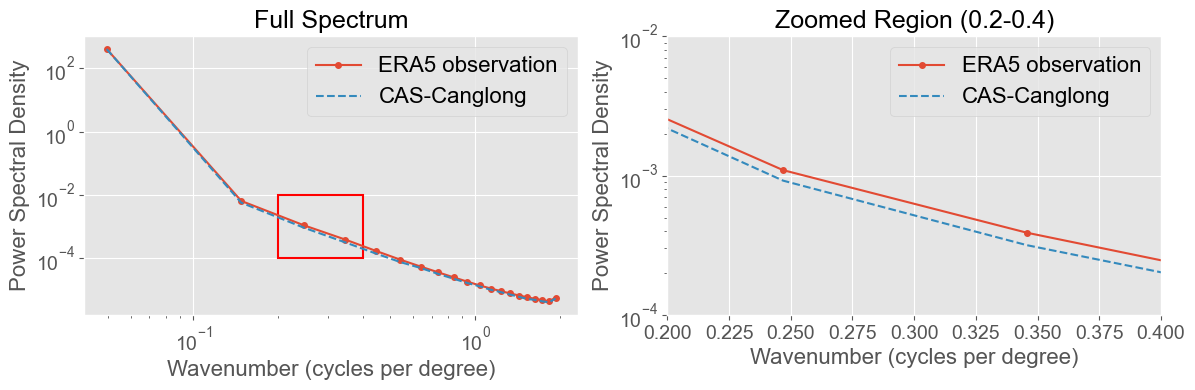

In [ ]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

def calculate_radial_psd(data_array, dx=None, dy=None):
    """
    计算二维 xarray DataArray 的径向平均功率谱密度。

    Args:
        data_array (xr.DataArray): 输入的二维空间数据 (例如，lat, lon)。
                                   假定坐标是均匀间隔的。
        dx (float, optional): x 方向（例如经度）的网格间距。
                              如果为 None，则尝试从坐标推断。
        dy (float, optional): y 方向（例如纬度）的网格间距。
                              如果为 None，则尝试从坐标推断。

    Returns:
        tuple: (wavenumber, psd)
            - wavenumber (np.ndarray): 径向波数 (单位: 1/坐标单位)。
            - psd (np.ndarray): 对应的功率谱密度。
    """
    # 确保输入是二维的
    if data_array.ndim != 2:
        raise ValueError("输入 DataArray 必须是二维的 (e.g., lat, lon)")

    # 获取维度名称和大小
    dims = data_array.dims
    shape = data_array.shape
    ny, nx = shape

    # 尝试从坐标推断网格间距 (假设是均匀的)
    if dx is None:
        lon_coord = data_array.coords[dims[1]] # 通常是经度
        # 处理经度可能跨越 0/360 度的情况
        lon_diff = np.diff(lon_coord)
        # 检查常见的跳跃（例如从 359.75 到 0）
        lon_jump = lon_coord[-1] - lon_coord[0] + lon_diff[0] # 估计完整范围的间距
        if np.isclose(lon_jump, 360.0) or np.isclose(lon_jump, 0.0):
             dx = np.mean(lon_diff)
        else: # 可能是非循环的或者部分区域
             dx = np.mean(np.diff(lon_coord))
        print(f"推断的 dx ({dims[1]} spacing): {dx:.4f}")

    if dy is None:
        lat_coord = data_array.coords[dims[0]] # 通常是纬度
        # 纬度通常不循环，直接计算平均间距
        dy = np.abs(np.mean(np.diff(lat_coord))) # 取绝对值，因为纬度可能递减
        print(f"推断的 dy ({dims[0]} spacing): {dy:.4f}")

    # 处理 NaN 值：移除包含 NaN 的区域，只使用有效数据
    if data_array.isnull().any():
        print("警告: 数据中包含 NaN 值，将只使用有效数据进行 FFT 计算。")
        # 创建一个掩码，标记所有非 NaN 值
        mask = ~np.isnan(data_array.values)
        if not np.any(mask):
            raise ValueError("数据全部为 NaN，无法计算 PSD。")
        
        # 提取非 NaN 区域的边界
        valid_rows = np.where(np.any(mask, axis=1))[0]
        valid_cols = np.where(np.any(mask, axis=0))[0]
        
        if len(valid_rows) == 0 or len(valid_cols) == 0:
            raise ValueError("没有足够的有效数据来计算 PSD。")
        
        # 提取有效数据区域
        data = data_array.values[np.ix_(valid_rows, valid_cols)]
        
        # 检查提取的数据是否仍然包含 NaN
        if np.isnan(data).any():
            # 如果仍有 NaN，使用掩码数组进行 FFT
            data = np.ma.masked_invalid(data)
            # 获取掩码数组的平均值
            mean_val = np.ma.mean(data)
            # 创建一个新数组，用平均值替换 NaN
            data_filled = data.filled(mean_val)
            # 使用填充后的数据
            data = data_filled
    else:
        data = data_array.values

    # 1. 计算二维傅里叶变换
    fft_result = np.fft.fft2(data)

    # 2. 计算功率谱 (|FFT|^2) 并进行归一化
    # 归一化使得总功率等于总方差 (Parseval 定理)
    power_spectrum_2d = np.abs(fft_result)**2 / (data.shape[0] * data.shape[1])**2

    # 3. 计算对应的波数 (kx, ky)
    # fftfreq 返回的是 周期数/采样间隔，这里采样间隔是 1 个点，所以需要乘以 1/dx
    kx = np.fft.fftfreq(data.shape[1], d=dx) # 波数单位: 1/dx单位
    ky = np.fft.fftfreq(data.shape[0], d=dy) # 波数单位: 1/dy单位

    # 4. 将零频率移到中心，方便计算径向波数
    power_spectrum_shifted = np.fft.fftshift(power_spectrum_2d)
    kx_shifted = np.fft.fftshift(kx)
    ky_shifted = np.fft.fftshift(ky)

    # 5. 创建二维波数网格
    kx_grid, ky_grid = np.meshgrid(kx_shifted, ky_shifted)

    # 6. 计算径向波数 k = sqrt(kx^2 + ky^2)
    # 注意：这里的波数单位是 1/坐标单位 (例如 1/degree)
    radial_wavenumber = np.sqrt(kx_grid**2 + ky_grid**2)

    # 7. 径向平均
    # 定义波数的 bin 边界。通常使用对数间隔的 bin，或者线性间隔。
    # 这里使用线性间隔的 bin 作为示例。
    # 最大波数由奈奎斯特频率决定 (约 1/(2*dx) 或 1/(2*dy))
    kmax = min(np.abs(kx_shifted).max(), np.abs(ky_shifted).max())
    # 定义 bin 数量，可以调整
    num_bins = min(data.shape[1] // 2, data.shape[0] // 2) // 2 # 经验性选择
    k_bins = np.linspace(0, kmax, num_bins + 1)
    k_bin_centers = (k_bins[:-1] + k_bins[1:]) / 2

    # 使用 np.histogram 将功率谱值分配到不同的径向波数 bin 中
    # 'weights=power_spectrum_shifted' 表示对功率谱值进行求和
    # 'bins=k_bins' 使用我们定义的波数 bin
    # 'density=False' (默认) 返回每个 bin 内权重的总和
    psd_sum_in_bin, _ = np.histogram(
        radial_wavenumber.ravel(),
        bins=k_bins,
        weights=power_spectrum_shifted.ravel()
    )

    # 计算每个 bin 中的点数，用于平均
    counts_in_bin, _ = np.histogram(
        radial_wavenumber.ravel(),
        bins=k_bins
    )

    # 计算平均 PSD
    # 避免除以零（如果某个 bin 中没有点）
    radial_psd = np.divide(
        psd_sum_in_bin,
        counts_in_bin,
        out=np.zeros_like(psd_sum_in_bin, dtype=float), # 如果 counts_in_bin 为 0，则结果为 0
        where=(counts_in_bin != 0)
    )

    # 返回 bin 的中心波数和对应的平均 PSD
    return k_bin_centers, radial_psd

# --- 主程序 ---
# 加载数据集


# 选择要分析的数据 (第一个时间步)，并截取南纬60度到南纬40度的区域
data_obs = ds['obs'][0].sel(lat=slice(-40, -60))    # 选择第一个时间步，并截取南纬60度到南纬40度
data_month1 = ds['month1'][0].sel(lat=slice(-40, -60)) # 选择第一个时间步，并截取南纬60度到南纬40度

# 检查数据维度是否正确
print("Data 'obs' shape:", data_obs.shape)
print("Data 'month1' shape:", data_month1.shape)
if data_obs.ndim != 2 or data_month1.ndim != 2:
     raise ValueError("选定的数据切片不是二维的。请确保选择了单个时间步。")


# 计算两个数据集的 PSD
# 网格间距可以手动指定，也可以让函数自动推断
# dx = 0.25 # 经度间距 (度)
# dy = 0.25 # 纬度间距 (度)
# k_obs, psd_obs = calculate_radial_psd(data_obs, dx=dx, dy=dy)
# k_month1, psd_month1 = calculate_radial_psd(data_month1, dx=dx, dy=dy)

# 让函数自动推断网格间距
print("\nCalculating PSD for 'obs'...")
k_obs, psd_obs = calculate_radial_psd(data_obs)

print("\nCalculating PSD for 'month1'...")
k_month1, psd_month1 = calculate_radial_psd(data_month1)


# 设置Arial字体
plt.rcParams['font.family'] = 'Arial'

# 创建一个包含两个子图的图形：主图和放大的窗口
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [1, 1]})
plt.style.use('ggplot')

# 主图 - 使用对数坐标轴
ax1.loglog(k_obs, psd_obs, label='ERA5 observation', marker='o', linestyle='-', markersize=4)
ax1.loglog(k_month1, psd_month1, label='CAS-Canglong', linestyle='--', markersize=4)
ax1.set_xlabel('Wavenumber (cycles per degree)', fontsize=16)
ax1.set_ylabel('Power Spectral Density', fontsize=16)
ax1.legend(fontsize=16)
ax1.tick_params(axis='both', labelsize=14)

# 放大的窗口 - 使用对数y轴，线性x轴
ax2.semilogy(k_obs, psd_obs, label='ERA5 observation', marker='o', linestyle='-', markersize=4)
ax2.semilogy(k_month1, psd_month1, label='CAS-Canglong', linestyle='--', markersize=4)
ax2.set_xlabel('Wavenumber (cycles per degree)', fontsize=16)
ax2.set_ylabel('Power Spectral Density', fontsize=16)
ax2.legend(fontsize=16)
ax2.tick_params(axis='both', labelsize=14)

# 设置放大窗口的范围：x从0.2到0.4，y从10^-4到10^-2
ax2.set_xlim(0.2, 0.4)
ax2.set_ylim(1e-4, 1e-2)

# 在主图上标记放大区域
# 创建一个矩形来表示放大区域
import matplotlib.patches as patches
rect = patches.Rectangle((0.2, 1e-4), 0.2, 1e-2-1e-4, linewidth=1.5, edgecolor='r', facecolor='none')
ax1.add_patch(rect)

# 添加标题
ax1.set_title('Full Spectrum', fontsize=18)
ax2.set_title('Zoomed Region (0.2-0.4)', fontsize=18)

plt.tight_layout() # 调整布局防止标签重叠
plt.show()

# 关闭数据集文件
ds.close()